# Exercícios 5.1 – 5.9 — Semana 5: From Language to Numbers

**Curso:** 02805 Social Graphs and Interactions (DTU, Fall 2026)
**Fonte:** [Week 5 page](https://sunelehmann.com/socialgraphs2026-web/weeks/week5.html) — "From language to numbers"
**Livro:** Jurafsky & Martin, *Speech and Language Processing* (draft de 19 ago 2026, grátis em [web.stanford.edu/~jurafsky/slp3](https://web.stanford.edu/~jurafsky/slp3/)) — Ch. 1 *Introduction*, Ch. 2 *Words and Tokens* (§2.1 palavras/types, §2.4 BPE, §2.8 tokenização por regras); [NLTK book, Ch. 1](https://www.nltk.org/book/ch01.html) para a Secção 3.

Este notebook resolve os 9 exercícios da Semana 5, pela ordem da página do curso. O texto de cada
exercício é citado em bloco (inglês, tal como está no site) e a resposta vem a seguir, **em português**.
Os exercícios 🧠 (à mão) são resolvidos passo a passo e **verificados em código** logo a seguir; os 🔬 correm
sobre o corpus Marvel e cada resposta cita os números que a célula imprimiu.

**Dados:** `data/marvel_pages.zip` da [data page](https://sunelehmann.com/socialgraphs2026-web/data/) (release da
semana 5, snapshot de 26 ago 2026): o texto completo da Wikipédia das **303 personagens** — os mesmos 303 nós de
`week1_nodes.tsv`, com a mesma chave `node_id`. 4 447 666 caracteres; páginas de 1 244 a 87 256 caracteres,
mediana 7 642 (os números da data page).

**Escolha de pré-processamento "principal"** (usada sempre que não se diga outra coisa): tokens do spaCy
(`en_core_web_sm`), minúsculas, sem pontuação, stopwords mantidas, sem lematização. Sob essa escolha o corpus
tem **744 495 tokens e 26 987 types**, 36.0% dos quais hapax. A página do curso fala em ≈727 000 tokens,
≈27 000 types e 36% — o mesmo retrato; a diferença nos tokens vem do tokenizer (ver 5.4.2 e 5.7.2).

**Teste 2 — quarta 4 nov, 08:30–09:30 (chegar 08:10), edifício 208 sala 054.** Cobre as semanas 5–8. Os 🧠
desta semana (5.1, 5.2, 5.6 e os itens 🧠 do 5.4 e 5.5) têm a forma das perguntas do teste.

## Setup

In [1]:
import sys
print(sys.executable)          # o Python que este notebook está mesmo a usar
%pip install spacy nltk tiktoken scikit-learn
!"{sys.executable}" -m spacy download en_core_web_sm

c:\Users\carlo\miniforge3\envs\dtu02452\python.exe
  Using cached spacy-3.8.16-cp312-cp312-win_amd64.whl.metadata (28 kB)
  Using cached tiktoken-0.14.0-cp312-cp312-win_amd64.whl.metadata (6.8 kB)
  Using cached spacy_legacy-3.0.12-py2.py3-none-any.whl.metadata (2.8 kB)
  Using cached spacy_loggers-1.0.5-py3-none-any.whl.metadata (23 kB)
  Using cached murmurhash-1.0.15-cp312-cp312-win_amd64.whl.metadata (2.3 kB)
  Using cached cymem-2.0.13-cp312-cp312-win_amd64.whl.metadata (9.9 kB)
  Using cached preshed-3.0.13-cp312-cp312-win_amd64.whl.metadata (5.4 kB)
  Using cached thinc-8.3.13-cp312-cp312-win_amd64.whl.metadata (15 kB)
  Using cached wasabi-1.1.3-py3-none-any.whl.metadata (28 kB)
  Using cached srsly-2.5.4-cp312-cp312-win_amd64.whl.metadata (20 kB)
  Using cached catalogue-2.0.10-py3-none-any.whl.metadata (14 kB)
  Using cached weasel-1.0.0-py3-none-any.whl.metadata (4.6 kB)
  Using cached confection-1.3.3-py3-none-any.whl.metadata (19 kB)
  Using cached typer-0.27.3-py3-none-an


[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


  Using cached https://github.com/explosion/spacy-models/releases/download/en_core_web_sm-3.8.0/en_core_web_sm-3.8.0-py3-none-any.whl (12.8 MB)
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')



[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [1]:
import re, zipfile, urllib.parse
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import spacy, nltk, tiktoken
from nltk import FreqDist
from nltk.text import Text
from nltk.util import ngrams
from nltk.collocations import BigramCollocationFinder, BigramAssocMeasures
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# primeira vez:  pip install spacy nltk tiktoken scikit-learn
#                python -m spacy download en_core_web_sm
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.width", 170); pd.set_option("display.max_colwidth", 60)

# rede da semana 1 (os mesmos 303 nós) + as páginas completas (snippet da data page)
nodes = pd.read_csv("../week1/data/week1_nodes.tsv", sep="\t", comment="#", quoting=3)
edges = pd.read_csv("../week1/data/week1_edges.tsv", sep="\t", comment="#", names=["source", "target"])
with zipfile.ZipFile("data/marvel_pages.zip") as z:
    marvel_pages = {
        urllib.parse.unquote(n.split("/")[-1][:-4]): z.read(n).decode("utf-8")
        for n in z.namelist()
        if n.endswith(".txt") and "README" not in n
    }
assert set(marvel_pages) == set(nodes.node_id)
IDS = list(nodes.node_id)                       # ordem fixa dos documentos = ordem do ficheiro de nós
name = dict(zip(nodes.node_id, nodes.name))

nlp = spacy.load("en_core_web_sm", disable=["parser", "ner"])   # tokenizer + tagger + lemmatizer chegam
enc = tiktoken.get_encoding("o200k_base")

chars = pd.Series({i: len(marvel_pages[i]) for i in IDS})
print(f"{len(marvel_pages)} páginas, {chars.sum():,} caracteres; "
      f"mín {chars.min():,} ({chars.idxmin()}), mediana {int(chars.median()):,}, máx {chars.max():,} ({chars.idxmax()})")

303 páginas, 4,447,666 caracteres; mín 1,244 (Helix_(Marvel_Comics)), mediana 7,642, máx 87,256 (Scarlet_Witch)


## Exemplos do texto da página (para correr enquanto lês)

Todos os blocos de Python da [página da semana 5](https://sunelehmann.com/socialgraphs2026-web/weeks/week5.html),
pela ordem em que aparecem, organizados pelas secções do texto. O código é o da página. Onde mudei alguma coisa,
há um comentário `# (alterado: …)`. Os comentários `# […]` que vêm da página são o output esperado.

Há dois exemplos que precisam do `marvel_tokens` (a *concordance* de *power* e as *collocations*). Esses estão mais
abaixo, no **Exercício 5.5**, porque o `marvel_tokens` só existe depois do pipeline do 5.3.

**Nomes repetidos.** O texto volta a usar nomes que o notebook usa mais à frente (`tokens`, `counts`, `doc`, `X`…).
Não há problema, porque os exercícios voltam a defini-los antes de os usar. A única exceção é o `nlp`: aqui chama-se
`nlp_full`, para não substituir o `nlp` do Setup.

### Secção 2 — From raw text to tokens

Partir nos espaços já é um tokenizer, e já faz escolhas:

In [2]:
raw = "Iron Man wasn't in New York."
raw.split()
# ['Iron', 'Man', "wasn't", 'in', 'New', 'York.']

['Iron', 'Man', "wasn't", 'in', 'New', 'York.']

O ponto fica colado a *York.* e *wasn't* fica inteiro. Para o `split()`, `York.` e `York` seriam dois types
diferentes.

**"Open up a Jupyter Notebook and play along as you read."** O spaCy faz a tokenização por palavras:

In [3]:
import spacy

# (alterado: na página é `nlp = spacy.load(...)`. Aqui chama-se nlp_full para não substituir o `nlp` do Setup,
#  que tem o parser e o NER desligados e é o que corre nas 303 páginas no 5.3. Este carrega o pipeline inteiro.)
nlp_full = spacy.load("en_core_web_sm")  # the whole English pipeline, not just a tokenizer
raw = "Marvel's heroes weren't fighting in New York."
doc = nlp_full(raw)

[t.text for t in doc]
# ['Marvel', "'s", 'heroes', 'were', "n't", 'fighting', 'in', 'New', 'York', '.']

['Marvel', "'s", 'heroes', 'were', "n't", 'fighting', 'in', 'New', 'York', '.']

Cada token traz informação agarrada (minúsculas, se é pontuação, se é stopword, o lema). Assim, as decisões de
pré-processamento podem ser tomadas mais tarde, sem perder o texto original:

In [4]:
lower = [t.text.lower() for t in doc]
no_punct = [t.text for t in doc if not t.is_punct]
no_stop = [t.text for t in doc if not t.is_stop]
lemmas = [t.lemma_ for t in doc]

# (alterado: a página só define as quatro listas; aqui imprimem-se para as comparar)
for label, lst in [("tokens", [t.text for t in doc]), ("lower", lower), ("no_punct", no_punct),
                   ("no_stop", no_stop), ("lemmas", lemmas)]:
    print(f"{label:9s} ({len(lst):2d}): {lst}")

tokens    (10): ['Marvel', "'s", 'heroes', 'were', "n't", 'fighting', 'in', 'New', 'York', '.']
lower     (10): ['marvel', "'s", 'heroes', 'were', "n't", 'fighting', 'in', 'new', 'york', '.']
no_punct  ( 9): ['Marvel', "'s", 'heroes', 'were', "n't", 'fighting', 'in', 'New', 'York']
no_stop   ( 6): ['Marvel', 'heroes', 'fighting', 'New', 'York', '.']
lemmas    (10): ['Marvel', "'s", 'hero', 'be', 'not', 'fight', 'in', 'New', 'York', '.']


### Secção 3 — Counting language, the old-school way

**Começar pelas contagens.** Um corpus de brincar com quatro frases, já tokenizado e em minúsculas, pequeno o
suficiente para conferir tudo à mão:

In [5]:
tokens = [
    "iron", "man", "fights", "the", "villain", ".",
    "the", "villain", "escapes", "to", "new", "york", ".",
    "iron", "man", "follows", "the", "villain", "to", "new", "york", ".",
    "the", "city", "thanks", "iron", "man", "."
]

len(tokens)

28

Contar cada type. No corpus Marvel, troca-se esta lista pelos tokens do pipeline escolhido:

In [6]:
from collections import Counter

counts = Counter(tokens)
counts.most_common(10)

[('the', 4),
 ('.', 4),
 ('iron', 3),
 ('man', 3),
 ('villain', 3),
 ('to', 2),
 ('new', 2),
 ('york', 2),
 ('fights', 1),
 ('escapes', 1)]

**Três verificações de sanidade:** quantos tokens, quantos types, quantos *hapax* (types que aparecem uma vez só).

In [7]:
n_tokens = len(tokens)
n_types = len(counts)
n_hapax = sum(n == 1 for n in counts.values())

n_tokens, n_types, n_hapax
# (28, 13, 5)

(28, 13, 5)

**Frequência relativa.** Comparar contagens brutas entre documentos de tamanhos diferentes engana, porque um documento
mais longo tem mais de quase tudo. Por isso divide-se pelo total de tokens:

In [8]:
total = len(tokens)
relative_frequency = {
    word: count / total
    for word, count in counts.items()
}

# (alterado: a página só define o dicionário; aqui mostram-se os 5 maiores e confirma-se que somam 1)
print({w: round(f, 3) for w, f in sorted(relative_frequency.items(), key=lambda kv: -kv[1])[:5]})
print("soma de todas as frequências relativas:", sum(relative_frequency.values()))

{'the': 0.143, '.': 0.143, 'iron': 0.107, 'man': 0.107, 'villain': 0.107}
soma de todas as frequências relativas: 1.0


**O mesmo com o `FreqDist` do NLTK**, que faz a mesma contagem e traz métodos de conveniência:

In [9]:
from nltk import FreqDist

fd = FreqDist(tokens)
# (alterado: na página as duas linhas seguintes não têm print. Num notebook só apareceria a última, por isso
#  aqui imprimem-se as duas.)
print(fd.most_common(10))
print(fd.hapaxes()[:10])

[('the', 4), ('.', 4), ('iron', 3), ('man', 3), ('villain', 3), ('to', 2), ('new', 2), ('york', 2), ('fights', 1), ('escapes', 1)]
['fights', 'escapes', 'follows', 'city', 'thanks']


**Python example: Zipf.** O gráfico frequência–rank parte das mesmas contagens. Ordena-se das mais frequentes
para as menos frequentes (rank 1 = a mais frequente) e desenha-se em eixos log-log:

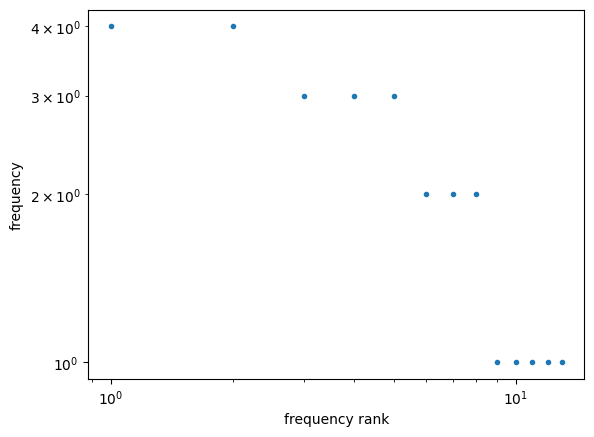

In [10]:
import matplotlib.pyplot as plt

frequencies = sorted(counts.values(), reverse=True)
ranks = range(1, len(frequencies) + 1)

plt.loglog(ranks, frequencies, ".")
plt.xlabel("frequency rank")
plt.ylabel("frequency")
plt.show()

Com 13 types isto são só patamares (4, 4, 3, 3, 3, 2, 2, 2, 1, …), não uma reta. Os gráficos frequência–rank no
corpus Marvel inteiro estão no **5.4**.

**Python example: concordance.** Este exemplo usa o `marvel_tokens` e por isso está no **Exercício 5.5**, logo antes
do 5.5.1.

**Python example: n-grams.** O `ngrams()` desliza uma janela de tamanho *n* pela sequência de tokens:

In [11]:
import spacy
from nltk.util import ngrams

# (alterado: na página é `nlp = spacy.load(...)`. Aqui chama-se nlp_full, como em cima, para não substituir
#  o `nlp` do Setup.)
nlp_full = spacy.load("en_core_web_sm")

sentence = "New York City is a city in the state of New York."
sentence_tokens = [t.text for t in nlp_full(sentence)]

list(ngrams(sentence_tokens, 2))[:5]

[('New', 'York'), ('York', 'City'), ('City', 'is'), ('is', 'a'), ('a', 'city')]

**Collocations.** Este exemplo também usa o `marvel_tokens`, por isso está no **Exercício 5.5**, logo antes do 5.5.3.
(A página avisa que, na frase de cima, o filtro de 5 ocorrências deitaria fora todos os bigramas.)

### Secção 4 — From words to documents

O Bag of Words com o `CountVectorizer`. Faz a mesma contabilidade da matriz construída à mão: tokenização,
vocabulário, contagens.

In [12]:
from sklearn.feature_extraction.text import CountVectorizer

documents = [
    "brains predict the future",
    "models predict the future",
    "brains build models"
]

vectorizer = CountVectorizer()
X = vectorizer.fit_transform(documents)

print(vectorizer.get_feature_names_out())
print(X.toarray())

['brains' 'build' 'future' 'models' 'predict' 'the']
[[1 0 1 0 1 1]
 [0 0 1 1 1 1]
 [1 1 0 1 0 0]]


A primeira linha são os nomes das colunas (o vocabulário, por ordem alfabética). A matriz tem uma linha por documento,
com as contagens.

### Secção 5 — Where counting stops

*(Extra: na página, estes dois exemplos são só texto. Aqui ficam em código para se verem os números.)*

1. Num Bag of Words, cada palavra é o seu próprio eixo. O cosseno entre dois eixos diferentes é sempre 0, por isso
   *dog* fica tão perto de *puppy* como de *democracy*.
2. Contar palavras isoladas deita fora a ordem. *the dog chased the ball* e *the ball chased the dog* têm o mesmo vetor.

In [13]:
# (extra: não é código da página)
from sklearn.metrics.pairwise import cosine_similarity

cv5 = CountVectorizer()
E = cv5.fit_transform(["dog", "puppy", "democracy"]).toarray()     # cada palavra = um vetor da base
print(cv5.get_feature_names_out()); print(E)
v = dict(zip(["dog", "puppy", "democracy"], E))
print("cosine(dog, puppy)     =", cosine_similarity([v["dog"]], [v["puppy"]])[0, 0])
print("cosine(dog, democracy) =", cosine_similarity([v["dog"]], [v["democracy"]])[0, 0])

cv5b = CountVectorizer()
B = cv5b.fit_transform(["the dog chased the ball", "the ball chased the dog"]).toarray()
print("\n", cv5b.get_feature_names_out()); print(B)
print("vetores iguais?", (B[0] == B[1]).all())

cv5c = CountVectorizer(ngram_range=(2, 2))     # com bigramas, a ordem volta a contar
Bc = cv5c.fit_transform(["the dog chased the ball", "the ball chased the dog"]).toarray()
print("\ncom bigramas:", cv5c.get_feature_names_out()); print(Bc)

['democracy' 'dog' 'puppy']
[[0 1 0]
 [0 0 1]
 [1 0 0]]
cosine(dog, puppy)     = 0.0
cosine(dog, democracy) = 0.0

 ['ball' 'chased' 'dog' 'the']
[[1 1 1 2]
 [1 1 1 2]]
vetores iguais? True

com bigramas: ['ball chased' 'chased the' 'dog chased' 'the ball' 'the dog']
[[0 1 1 1 1]
 [1 1 0 1 1]]


## Exercício 5.1 — Did you really read it? · language and tokens (🧠 learn)

> No notebook, no chatbot. Think, then write.
>
> 1. The toy next-token generator at the start of the page already assumes that the text has been split into tokens and that a probability table exists for what comes next. In a real system, which part is decided by the tokenizer before the language model sees the text, and which part must the language model learn from training data?
> 2. Explain the difference between a token, a type, and a vocabulary using a sentence of your own. Then say exactly what can happen to the number of types if you lowercase the sentence.
> 3. Put these in the right order and explain what each step does: token IDs, raw characters, tokenizer, model, token pieces. Which step decides that *New York* is two pieces rather than one?
> 4. Lowercasing, stopword removal and lemmatization all throw information away. Pick one of them. Give one research question where it would probably be harmless, and one where it could destroy the signal you care about.
> 5. This one is about the reading. Jurafsky & Martin (Chapter 2) describe how byte-pair encoding (BPE) builds a subword vocabulary. In your own words, what does BPE start from, what does it repeat, and when does it stop? Why does starting from single characters mean no word is ever completely unknown to the model?

### 5.1.1 — O que decide o tokenizer e o que aprende o modelo

- **Tokenizer (fixo, antes de o modelo ver o texto):** onde ficam as fronteiras — em que unidades o texto é
  cortado — e o **vocabulário fixo** que faz corresponder cada unidade a um *token ID*. O modelo não tem voto
  nisto: só recebe a sequência de inteiros.
- **Modelo de linguagem (aprendido dos dados de treino):** as **probabilidades** — dados os tokens até
  agora, quão provável é cada token do vocabulário vir a seguir — e, com elas, a representação interna de cada
  token. No explorable da página essa tabela foi escrita à mão; num sistema real é o que o treino produz.

(O vocabulário de subpalavras também é *induzido* de um corpus, pelo BPE — mas num passo separado, antes do
treino do modelo, e depois fica congelado.)

### 5.1.2 — Token, type, vocabulário

Frase: *The hero saved the city and the villain.* (sem contar o ponto final)

| | contagem | o que é |
|---|---:|---|
| **tokens** | 8 | ocorrências: The · hero · saved · the · city · and · the · villain |
| **types** (com maiúsculas) | 7 | formas distintas: *The, hero, saved, the, city, and, villain* — *the* aparece 2× e conta 1×; *The* é outro type |
| **vocabulário** | — | o conjunto desses 7 types |

Depois de passar a minúsculas, *The* e *the* fundem-se: **6 types**; os tokens continuam 8.

**Regra geral.** Minúsculas nunca alteram o número de tokens. O número de types **ou fica igual** (se não
havia dois types a diferir só na capitalização) **ou diminui**. Nunca aumenta.

### 5.1.3 — A ordem do pipeline

**raw characters → tokenizer → token pieces → token IDs → model**

1. *raw characters* — o texto como uma string, sem unidades.
2. *tokenizer* — as regras (ou o procedimento treinado) que decidem onde acaba cada unidade.
3. *token pieces* — as unidades resultantes (palavras, pontuação, subpalavras).
4. *token IDs* — cada peça substituída pelo seu índice inteiro no vocabulário do modelo.
5. *model* — recebe só os IDs e prevê o próximo.

Quem decide que *New York* são duas peças é o **tokenizer**.

### 5.1.4 — Uma escolha: minúsculas

- **Inofensivo:** "de que temas falam as páginas de duas comunidades Marvel?" — *Power* no início de uma
  frase e *power* a meio são a mesma palavra para essa pergunta.
- **Destrói o sinal:** "quantas vezes se fala de tempestades (*storm*)?" — no corpus Marvel, 97% das
  ocorrências de *storm* depois do lowercase são a personagem **Storm** (está medido no 5.3.4). O mesmo com
  *Vision*/*vision*, *Apple*/*apple*, *US*/*us*: a maiúscula é exatamente o que as distingue.

(O mesmo padrão para as outras. *Stopwords*: inofensivo para temas, fatal para a negação — *not* e *n't* são
stopwords — e para estilo/autoria. *Lematização*: inofensiva para temas, fatal se a pergunta é sobre o tempo
verbal, p. ex. se as personagens mortas são descritas no passado.)

### 5.1.5 — BPE (J&M §2.4)

- **Começa** com um vocabulário que contém todos os **caracteres individuais** (na prática, os 256 bytes do
  UTF-8) e com o corpus de treino partido nesses caracteres.
- **Repete:** conta todos os pares de tokens adjacentes → pega no **par mais frequente** → funde-o num token
  novo → junta-o ao vocabulário → substitui todas as ocorrências do par no corpus. (As fusões não atravessam
  fronteiras de palavra.)
- **Pára** ao fim de $k$ fusões; $k$ é o parâmetro que se escolhe. Vocabulário final = caracteres $+\ k$ tokens fundidos.

Exemplo do livro: corpus `A B D C A B E C A B` → par mais frequente `A B` (3×) → `AB D C AB E C AB` → par
mais frequente `C AB` (2×) → `AB D CAB E CAB`. Duas fusões, dois tokens novos; o corpus passou de 10 para 7 para 5.

**Porque é que nenhuma palavra é desconhecida:** os caracteres soltos nunca saem do vocabulário. Qualquer
palavra, por mais nova que seja, pode — no pior caso — ser escrita como a sequência dos seus caracteres.
Palavras frequentes ficam com 1 token, raras com algumas peças, e nada fica "fora do vocabulário".

## Exercício 5.2 — Tokenization, by hand (🧠 learn)

> Paper first. The point is to make the choices visible before a library makes them for us.
>
> 1. Start with *Spider-Man didn't save Queens; Doctor Strange's portal did!* Before you split anything, write down your rules: what happens to hyphens, apostrophes and punctuation? Then tokenize the sentence by hand and report the number of tokens and types. Keep your answer, because you will check it against spaCy in 5.3.
> 2. Now predict, without running code, what happens to the token and type counts after lowercasing and after removing punctuation. Then define a small stopword set of your own, remove it, and predict the counts again. Some counts may stay the same. Say why.
> 3. *New York* remaining as two tokens is not a tokenizer failure. What later NLP task could decide that the two tokens together refer to one place? Give one more example where token boundaries and the thing we care about are not the same.
> 4. Now play subword tokenizer. Your whole vocabulary is the pieces *un, believ, able, spider, man, hat, tan, wak, anda*, plus every single letter. Lowercase each word, then split it from left to right, always taking the longest piece in the vocabulary that fits. Segment *unbelievable*, *Spiderman*, *Wakanda*, *Manhattan* and *Thanos*. Which word costs the most tokens, and why is that still better than having no representation for it at all?
> 5. Suppose your question is whether the word *power* is used differently across two Marvel communities. Would you lowercase? Lemmatize? Remove stopwords? There is no universal answer here. Make the choices you would use and defend them. Careful with the last one: if you compare how often *power* occurs relative to the total number of tokens, does removing stopwords change that number even though no *power* token was removed?

### 5.2.1 — Primeiro as regras, depois os tokens

As minhas regras (a convenção Penn Treebank do J&M §2.8):

1. corta-se nos espaços;
2. **hífen** dentro de uma palavra **fica** — *Spider-Man* é um token;
3. **apóstrofo:** os clíticos separam-se — *didn't* → *did* + *n't*; *Strange's* → *Strange* + *'s*;
4. **pontuação:** cada sinal é um token próprio.

| # | 1 | 2 | 3 | 4 | 5 | 6 | 7 | 8 | 9 | 10 | 11 | 12 |
|---|---|---|---|---|---|---|---|---|---|---|---|---|
| token | Spider-Man | did | n't | save | Queens | ; | Doctor | Strange | 's | portal | did | ! |

**12 tokens, 11 types** (*did* aparece duas vezes e conta uma).

Outras regras dão outras respostas igualmente defensáveis: um `split()` nos espaços dá 8 tokens e 8 types
(*didn't*, *Queens;*, *Strange's*, *did!* ficam colados — e os dois *did* deixam de ser o mesmo type).

### 5.2.2 — Previsões

Ponto de partida: 12 tokens, 11 types.

**Minúsculas.** *Truque — o lowercase nunca apaga tokens; só funde types que diferem apenas na capitalização.*
Aqui não há nenhum par assim (os dois *did* já eram iguais):
$$
\text{tokens} = 12, \qquad \text{types} = 11 \quad \text{(nada muda)}
$$

**Tirar a pontuação** (`;` e `!`). Saem 2 tokens, e cada um era o seu próprio type:
$$
\text{tokens} = 12 - 2 = 10, \qquad \text{types} = 11 - 2 = 9
$$

**Tirar as stopwords** — o meu conjunto: $\{\textit{did},\ \textit{n't},\ \textit{'s}\}$. Saem 4 tokens
(*did* ×2, *n't*, *'s*) mas só 3 types, porque os dois *did* eram um só type:
$$
\text{tokens} = 10 - 4 = 6, \qquad \text{types} = 9 - 3 = 6
$$

Sobra: *spider-man, save, queens, doctor, strange, portal* — as palavras de conteúdo. Repara no que se perdeu:
*n't* era stopword, por isso os tokens que restam já não dizem que o Homem-Aranha **não** salvou Queens.

**Porque é que algumas contagens ficam iguais:** uma operação que só *renomeia* tokens (lowercase,
lematização) não muda o número de tokens; e só muda o número de types quando duas formas distintas passam a
ser a mesma. Uma operação que *remove* tokens (pontuação, stopwords) baixa os tokens pelo número de
ocorrências e os types pelo número de formas distintas removidas.

### 5.2.3 — *New York*

A tarefa é o **reconhecimento de entidades nomeadas** (*named entity recognition*, NER): detetar nomes de
lugares, pessoas e organizações — é ela (ou um dicionário de expressões multi-palavra) que decide que
*New* + *York* é um só lugar. O tokenizer só decide as unidades; juntá-las em coisas com significado é trabalho posterior.

Outros exemplos em que fronteira de token ≠ aquilo que nos interessa: *Doctor Strange* e *Iron Man* (dois
tokens, uma personagem); *rock 'n' roll*; *didn't* (uma palavra ortográfica, duas gramaticais); num
tokenizer de subpalavras, um nome raro partido em três peças continua a ser um só nome.

### 5.2.4 — Tokenizer de subpalavras, à mão

Regra: da esquerda para a direita, a **maior** peça do vocabulário que couber.

| palavra | segmentação | tokens |
|---|---|---:|
| unbelievable | un · believ · able | 3 |
| spiderman | spider · man | 2 |
| wakanda | wak · anda | 2 |
| manhattan | man · hat · tan | 3 |
| thanos | t · h · a · n · o · s | **6** |

*Thanos*, passo a passo: em *t*, a única peça com mais de uma letra que começa por *t* é *tan*, mas o texto
diz *tha* → fica *t*. Em *h*: *hat* não cabe em *han* → *h*. Em *a*: nem *able* nem *anda* cabem em *ano* → *a*.
Depois *n*, *o*, *s*.

**Thanos é a que custa mais: 6 tokens, um por letra**, porque nenhuma peça do vocabulário encaixa. Mesmo
assim é melhor do que não ter representação: com um vocabulário de palavras inteiras, *Thanos* seria um
símbolo "desconhecido" igual a todas as outras palavras desconhecidas — o modelo não o conseguiria ler nem
escrever. Em seis letras fica exatamente representado e distinguível; só sai mais caro (sequência mais longa,
menos significado por token).

Nota: *man · hat · tan* não é uma divisão com sentido (Manhattan não tem nada a ver com chapéus). As peças
de subpalavras são estatísticas, não são morfemas.

### 5.2.5 — *power* em duas comunidades: as minhas escolhas

- **Minúsculas: sim.** *Power* no início de frase é a mesma palavra. Custo a verificar no texto: nomes como
  *Power Pack* ou *Power Man* entram na contagem (no corpus, 27% das ocorrências de *power* têm maiúscula —
  5.3.4); se forem muitos numa das comunidades, trato-os à parte.
- **Lematizar: não (ou só no fim).** Juntar *power* e *powers* é razoável para "quantas vezes"; mas
  *powers and abilities* (título de secção), *the power to…* e *in power* são precisamente as diferenças de
  **uso** que a pergunta quer ver. Contava as formas em separado primeiro.
- **Stopwords: manter.** O uso está no contexto — *the power of*, *in power*, *her powers* — e sem as palavras
  funcionais a concordância e os bigramas perdem o que distingue os usos.

**A armadilha.** Sim, a frequência relativa muda, mesmo sem se remover nenhum *power*: o **denominador** encolhe.
$$
\text{antes:}\quad \frac{50}{10\,000} = 0.50\%
$$
$$
\text{depois de tirar 4 000 stopwords:}\quad \frac{50}{10\,000 - 4\,000} = \frac{50}{6\,000} = 0.83\%
$$
Pior: se as páginas das duas comunidades tiverem proporções diferentes de stopwords, a remoção desloca as
duas frequências relativas por fatores diferentes e pode **criar ou esconder** uma diferença. Seja qual for a
escolha: a mesma para as duas comunidades, e dita por escrito.

In [14]:
# Verificação do 5.2 -- as MINHAS regras escritas como um tokenizer de 1 linha
SENT = "Spider-Man didn't save Queens; Doctor Strange's portal did!"
RULES = r"\w+(?=n't)|n't|'s|\w+(?:-\w+)*|[^\w\s]"     # clíticos separados · hífen interno fica · pontuação à parte
hand = re.findall(RULES, SENT)

def report(label, toks):
    print(f"{label:34s} tokens = {len(toks):2d}   types = {len(set(toks)):2d}   {toks}")

report("5.2.1  regras à mão", hand)
low = [t.lower() for t in hand];                      report("5.2.2  + minúsculas", low)
nop = [t for t in low if re.search(r"\w", t)];        report("       + sem pontuação", nop)
MY_STOP = {"did", "n't", "'s"}
nos = [t for t in nop if t not in MY_STOP];           report("       + sem stopwords {did,n't,'s}", nos)
report("(comparação) str.split()", SENT.split())

# 5.2.4 -- tokenizer de subpalavras "guloso": da esquerda para a direita, a maior peça que couber
PIECES = {"un", "believ", "able", "spider", "man", "hat", "tan", "wak", "anda"}
def greedy(word, vocab=PIECES):
    word, out, i = word.lower(), [], 0
    while i < len(word):
        for L in range(len(word) - i, 0, -1):          # tenta a peça mais comprida primeiro
            piece = word[i:i + L]
            if piece in vocab or L == 1:               # todas as letras soltas estão no vocabulário
                out.append(piece); i += L; break
    return out
print()
for w in ["unbelievable", "Spiderman", "Wakanda", "Manhattan", "Thanos"]:
    seg = greedy(w); print(f"{w:13s} -> {' · '.join(seg):28s} {len(seg)} tokens")

5.2.1  regras à mão                tokens = 12   types = 11   ['Spider-Man', 'did', "n't", 'save', 'Queens', ';', 'Doctor', 'Strange', "'s", 'portal', 'did', '!']
5.2.2  + minúsculas                tokens = 12   types = 11   ['spider-man', 'did', "n't", 'save', 'queens', ';', 'doctor', 'strange', "'s", 'portal', 'did', '!']
       + sem pontuação             tokens = 10   types =  9   ['spider-man', 'did', "n't", 'save', 'queens', 'doctor', 'strange', "'s", 'portal', 'did']
       + sem stopwords {did,n't,'s} tokens =  6   types =  6   ['spider-man', 'save', 'queens', 'doctor', 'strange', 'portal']
(comparação) str.split()           tokens =  8   types =  8   ['Spider-Man', "didn't", 'save', 'Queens;', 'Doctor', "Strange's", 'portal', 'did!']

unbelievable  -> un · believ · able           3 tokens
Spiderman     -> spider · man                 2 tokens
Wakanda       -> wak · anda                   2 tokens
Manhattan     -> man · hat · tan              3 tokens
Thanos        -> t · h · a

A verificação confirma as quatro linhas de contagens (12/11 → 12/11 → 10/9 → 6/6) e as cinco segmentações.

## Exercício 5.3 — Tokenization, as code (🔬 tool)

> Now let the machine do the boring part, but make it show its work.
>
> 1. Run the sentence from 5.2 through spaCy and through the subword tokenizer used by recent OpenAI models: `tiktoken.get_encoding("o200k_base")`. `encode()` returns bare token IDs, so decode them one at a time to see the pieces: `[enc.decode([i]) for i in ids]`. Put spaCy's tokens, your hand tokenization and the subword pieces next to each other. Find at least two disagreements and explain why each tokenizer made its choice. (Look closely at the spaces.)
> 2. Have your agent build a table with token text, lowercase form, `is_stop`, `is_punct` and lemma. Check at least three rows yourself against the raw sentence before trusting the table.
> 3. Run the same pipeline on one Marvel page. Report the raw character count, token count, type count and the five most frequent types before and after one preprocessing choice of your own. Inspect the underlying text for anything that surprises you.
> 4. Find one tokenization or preprocessing decision that would actually change the answer to a plausible research question about the Marvel corpus. Show the before and after, then write three sentences on why the difference matters.
> 5. Test Heaps' law on Marvel. Read through the pages one at a time and plot the number of types seen so far against the number of tokens seen so far. Does the curve flatten out? Then take every Marvel type that occurs at least once and count how many the `o200k_base` tokenizer splits into more than one piece. Which kinds of words get split, and what does that tell you about why modern models use subwords?

In [15]:
# 5.3.1 -- à mão vs spaCy vs o200k_base
doc = nlp(SENT)
spacy_toks = [t.text for t in doc]
ids = enc.encode(SENT)
pieces = [enc.decode([i]) for i in ids]

print(f"à mão  ({len(hand):2d}): {hand}")
print(f"spaCy  ({len(spacy_toks):2d}): {spacy_toks}")
print(f"o200k  ({len(pieces):2d}): {pieces}")
print(f"IDs          : {ids}")
print("\ncom e sem espaço à frente são tokens diferentes:",
      {repr(s): enc.encode(s) for s in ["save", " save", "Man", "-Man", " didn't", "didn't"]})

à mão  (12): ['Spider-Man', 'did', "n't", 'save', 'Queens', ';', 'Doctor', 'Strange', "'s", 'portal', 'did', '!']
spaCy  (14): ['Spider', '-', 'Man', 'did', "n't", 'save', 'Queens', ';', 'Doctor', 'Strange', "'s", 'portal', 'did', '!']
o200k  (12): ['Spider', '-Man', " didn't", ' save', ' Queens', ';', ' Doctor', ' Strange', "'s", ' portal', ' did', '!']
IDs          : [105564, 59466, 9289, 5093, 44979, 26, 28570, 101854, 885, 26883, 2242, 0]

com e sem espaço à frente são tokens diferentes: {"'save'": [13158], "' save'": [5093], "'Man'": [2246], "'-Man'": [59466], '" didn\'t"': [9289], '"didn\'t"': [38820, 3023]}


**5.3.1 — Três tokenizers, três respostas.**

| | à mão (12) | spaCy (14) | o200k_base (12) |
|---|---|---|---|
| *Spider-Man* | `Spider-Man` | `Spider` · `-` · `Man` | `Spider` · `-Man` |
| *didn't* | `did` · `n't` | `did` · `n't` | `␣didn't` (uma peça) |
| *Strange's* | `Strange` · `'s` | `Strange` · `'s` | `␣Strange` · `'s` |
| espaços | deitados fora | deitados fora | **colados ao início** da peça seguinte |

**Desacordo 1 — o hífen.** Eu mantive *Spider-Man* inteiro (regra Penn Treebank: é um nome). O spaCy tem uma
regra de *infixo* que corta os hífenes entre letras, e dá três tokens — útil para *well-known*, mau para
nomes. O o200k não tem regras linguísticas: o BPE aprendeu que `-Man` é uma sequência frequente e fez dela
uma peça.

**Desacordo 2 — a contração.** À mão e no spaCy, *didn't* → *did* + *n't*: são tokenizers feitos para
análise linguística, e a negação é uma palavra gramatical à parte. No o200k, `␣didn't` é **uma só peça**
(ID 9289): a string é tão frequente que as fusões do BPE a juntaram toda. Ninguém "decidiu" isso — foram as
contagens.

**Os espaços.** O spaCy descarta-os (guarda-os como atributo do token). O o200k cola o espaço à frente da
palavra, para que descodificar os IDs devolva **exatamente** o texto original. Consequência: `save` (13158) e
`␣save` (5093) são tokens diferentes, e `didn't` **sem** espaço à frente já são duas peças (38820, 3023).

À mão e o200k dão ambos 12 — coincidência: as unidades não são as mesmas.

In [16]:
# 5.3.2 -- a tabela (uma linha por token do spaCy)
tab = pd.DataFrame([dict(text=t.text, lower=t.lower_, is_stop=t.is_stop, is_punct=t.is_punct, lemma=t.lemma_)
                    for t in doc])
print(tab.to_string())

       text    lower  is_stop  is_punct    lemma
0    Spider   spider    False     False   Spider
1         -        -    False      True        -
2       Man      man    False     False      Man
3       did      did     True     False       do
4       n't      n't     True     False      not
5      save     save    False     False     save
6    Queens   queens    False     False   Queens
7         ;        ;    False      True        ;
8    Doctor   doctor    False     False   Doctor
9   Strange  strange    False     False  Strange
10       's       's     True     False       's
11   portal   portal    False     False   portal
12      did      did     True     False       do
13        !        !    False      True        !


**5.3.2 — Três linhas conferidas contra a frase.**

- **Linha 3, `did`:** `lower` = *did*, `is_stop` = True, `lemma` = **do**. Certo — é o passado de *do*, e é palavra funcional.
- **Linha 4, `n't`:** `is_stop` = True, `lemma` = **not**. Certo — e é o aviso do 5.2.2: tirar stopwords apaga a negação.
- **Linha 6, `Queens`:** `lemma` = **Queens**, não *queen*. Certo — o spaCy reconhece o nome próprio e não o reduz ao singular.

Também a conferir: `-`, `;` e `!` têm `is_punct` = True; `'s` é stopword; *Spider* e *Man* ficam como dois
tokens de conteúdo (a diferença para a minha tokenização à mão).

### O pipeline para o corpus inteiro

A partir daqui, tudo corre sobre as 303 páginas. O spaCy é corrido **uma vez** e a função `toks()` aplica as
escolhas de pré-processamento *depois* da tokenização — a ordem que a página pede para manter na cabeça.

In [17]:
# O pipeline da semana: spaCy em todas as páginas (≈ 1 min), uma vez só.
docs = dict(zip(IDS, nlp.pipe([marvel_pages[i] for i in IDS], batch_size=20)))

def toks(doc, lower=True, punct=False, stop=True, lemma=False):
    """Lista de tokens de um Doc. Espaços/newlines nunca contam como tokens."""
    out = []
    for t in doc:
        if t.is_space: continue
        if not punct and t.is_punct: continue
        if not stop and t.is_stop: continue
        w = t.lemma_ if lemma else t.text
        out.append(w.lower() if lower else w)
    return out

# ESCOLHA DE PRÉ-PROCESSAMENTO (a "principal" deste notebook):
#   tokens do spaCy · minúsculas · sem pontuação · stopwords mantidas · sem lematização
marvel_tokens = [w for i in IDS for w in toks(docs[i])]
print(f"corpus Marvel sob a escolha principal: {len(marvel_tokens):,} tokens, {len(set(marvel_tokens)):,} types")

corpus Marvel sob a escolha principal: 744,495 tokens, 26,987 types


In [18]:
# 5.3.3 -- uma página: Wolverine
PID = "Wolverine_(character)"
d = docs[PID]
before = toks(d)                      # escolha principal
after  = toks(d, stop=False)          # UMA escolha a mais: remover stopwords
cb, ca = Counter(before), Counter(after)
print(f"{name[PID]}: {len(marvel_pages[PID]):,} caracteres em bruto")
print(f"antes  (stopwords mantidas): {len(before):6,} tokens, {len(cb):5,} types | top 5: {cb.most_common(5)}")
print(f"depois (sem stopwords)     : {len(after):6,} tokens, {len(ca):5,} types | top 5: {ca.most_common(5)}")
print(f"\nremovidos: {len(before) - len(after):,} tokens ({1 - len(after)/len(before):.0%}) mas só {len(cb) - len(ca)} types")
print("top 15 sem stopwords:", ca.most_common(15))

Wolverine (character): 47,074 caracteres em bruto
antes  (stopwords mantidas):  7,601 tokens, 2,024 types | top 5: [('the', 387), ('and', 257), ('wolverine', 251), ('of', 223), ('in', 217)]
depois (sem stopwords)     :  4,341 tokens, 1,849 types | top 5: [('wolverine', 251), ('x', 112), ('men', 84), ('logan', 45), ('series', 38)]

removidos: 3,260 tokens (43%) mas só 175 types
top 15 sem stopwords: [('wolverine', 251), ('x', 112), ('men', 84), ('logan', 45), ('series', 38), ('character', 36), ('marvel', 27), ('claremont', 25), ('new', 21), ('adamantium', 19), ('weapon', 19), ('canadian', 19), ('comic', 18), ('written', 18), ('story', 18)]


In [19]:
# inspecionar o texto por baixo das surpresas: de onde vêm "x", "men" e "'s"?
T_w = Text(before)
T_w.concordance("x", width=78, lines=4)
raw = marvel_pages[PID]
print("\n'X-Men' no texto em bruto:", len(re.findall(r"X-Men", raw)), "| 'x' como token:", cb["x"], "| 'men':", cb["men"])
print("\"'s\" como token:", cb["'s"], "| exemplos:", re.findall(r"\w+'s \w+", raw)[:4])
print("fim da página:", repr(raw[-160:]))

Displaying 4 of 112 matches:
as a member of the superhero team the x men wolverine is the alias of james h
 unwilling test subject in the weapon x super soldier program wolverine is co
les xavier to join his second team of x men and has since been one of their k
ne of their key members since joining x men wolverine has built strong relati

'X-Men' no texto em bruto: 83 | 'x' como token: 112 | 'men': 84
"'s" como token: 108 | exemplos: ["character's catchphrase", "Wolverine's mental", "character's appeal", "Wolverine's first"]
fim da página: 'mes, is set to release in 2026.\n\n\nReferences\n\n\nBibliography\n\n\nExternal links\nWolverine (Logan/James Howlett) at Marvel.com\nWolverine (Earth-58163) at Marvel.com'


**5.3.3 — Uma página: Wolverine.** A escolha extra é **remover stopwords**.

| | caracteres | tokens | types | top 5 |
|---|---:|---:|---:|---|
| antes (escolha principal) | 47 074 | 7 601 | 2 024 | the 387, and 257, wolverine 251, of 223, in 217 |
| depois (sem stopwords) | | 4 341 | 1 849 | wolverine 251, x 112, men 84, logan 45, series 38 |

Saem **43% dos tokens** mas só **175 types** (9%): as stopwords são poucas formas com muitas ocorrências.

**O que me surpreendeu, depois de ir ao texto:**

- **`x` e `men` são a 2ª e 3ª palavras de conteúdo.** Não são palavras: é *X-Men* (83 vezes no texto) partido
  pelo spaCy no hífen; os outros `x` vêm de *Weapon X*. Uma lista de "palavras mais frequentes" feita assim
  estaria a mostrar uma decisão do tokenizer.
- **`'s` é um token** (108 vezes — *Wolverine's*, *character's*) e só desaparece por ser stopword.
- **`claremont` (25) e `series`, `written`, `comic`** estão no topo: a página é tanto sobre a *história editorial*
  (Chris Claremont é o argumentista) como sobre a personagem.
- **O fim da página** são os cabeçalhos *References / Bibliography / External links* e links para o Marvel.com —
  texto de estrutura da Wikipédia que entra nas contagens de todas as páginas.

In [20]:
# 5.3.4 -- uma decisão que muda a resposta: minúsculas, quando o nome da personagem é uma palavra comum
cased = Counter(w for i in IDS for w in toks(docs[i], lower=False))
lowc = Counter(marvel_tokens)
rows = []
for w in ["storm", "vision", "thing", "beast", "power"]:
    cap = cased[w.capitalize()]; lo = cased[w]
    rows.append(dict(palavra=w, com_maiuscula=cap, minuscula=lo, depois_de_lowercase=lowc[w],
                     pct_com_maiuscula=f"{cap / (cap + lo):.0%}"))
print(pd.DataFrame(rows).to_string(index=False))
N = len(marvel_tokens)
print(f"\n'storm' por 10 000 tokens: sem lowercase {1e4 * cased['storm'] / N:.2f}  ->  com lowercase {1e4 * lowc['storm'] / N:.2f}"
      f"   (×{lowc['storm'] / cased['storm']:.0f})")

palavra  com_maiuscula  minuscula  depois_de_lowercase pct_com_maiuscula
  storm            405         12                  417               97%
 vision            131         60                  191               69%
  thing            263         59                  322               82%
  beast             85         12                   97               88%
  power            225        595                  820               27%

'storm' por 10 000 tokens: sem lowercase 0.16  ->  com lowercase 5.60   (×35)


**5.3.4 — Uma decisão que muda a resposta: minúsculas.**

Pergunta plausível: *"Quanto é que as páginas Marvel falam de fenómenos naturais — por exemplo, com que
frequência aparece **storm**?"*

- **Sem lowercase:** `storm` aparece **12** vezes (0.16 por 10 000 tokens).
- **Com lowercase:** **417** vezes (5.60 por 10 000) — **35 vezes mais**.

As três frases: (1) Em 97% das ocorrências, *storm* é a personagem **Storm** dos X-Men, e o lowercase funde-a
com a palavra comum — a resposta "fala-se muito de tempestades" seria um artefacto. (2) O mesmo acontece com
todas as personagens cujo nome é uma palavra corrente (*Vision* 69%, *Thing* 82%, *Beast* 88%), por isso
qualquer análise de *temas* neste corpus fica contaminada por nomes próprios. (3) Não há uma escolha
"certa": para contar menções à personagem o lowercase também estraga (junta-lhe as 12 tempestades), e sem
lowercase perde-se *Power* em início de frase — a decisão tem de ser tomada **para a pergunta** e escrita no relatório.

ajuste |V| = k·N^β :  β = 0.526,  k = 23.2
páginas   1–100:  161.0 types novos por página,  68.7 por 1000 tokens
páginas 101–200:   65.5 types novos por página,  24.8 por 1000 tokens
páginas 201–303:   42.1 types novos por página,  17.6 por 1000 tokens


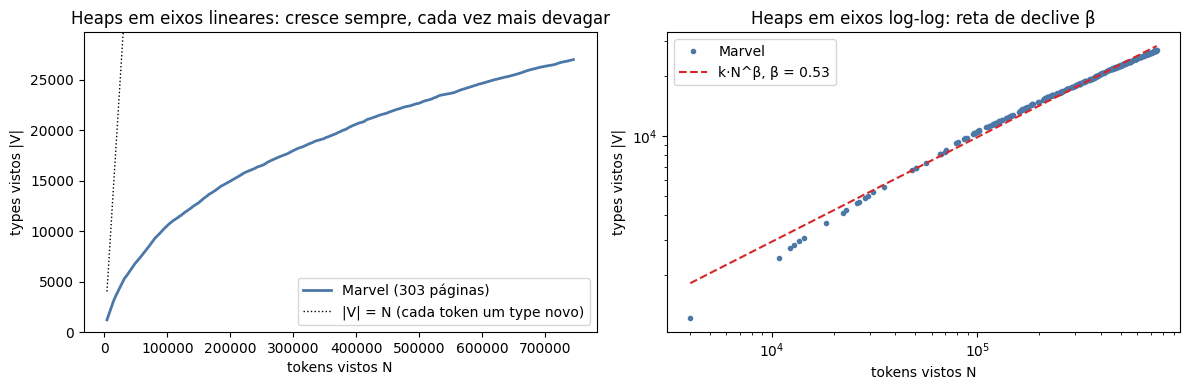

In [21]:
# 5.3.5 (a) -- lei de Heaps: types vistos vs tokens vistos, lendo as páginas uma a uma
def heaps_curve(order):
    seen, n, N_, V_ = set(), 0, [], []
    for i in order:
        t = toks(docs[i]); n += len(t); seen.update(t)
        N_.append(n); V_.append(len(seen))
    return np.array(N_), np.array(V_)

Nh, Vh = heaps_curve(IDS)
beta, logk = np.polyfit(np.log(Nh), np.log(Vh), 1)
print(f"ajuste |V| = k·N^β :  β = {beta:.3f},  k = {np.exp(logk):.1f}")
for a, b in [(0, 99), (100, 199), (200, 302)]:
    print(f"páginas {a + 1:3d}–{b + 1:3d}: {(Vh[b] - (Vh[a - 1] if a else 0)) / (b - a + 1):6.1f} types novos por página, "
          f"{1000 * (Vh[b] - (Vh[a - 1] if a else 0)) / (Nh[b] - (Nh[a - 1] if a else 0)):5.1f} por 1000 tokens")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(Nh, Vh, color="#4c78a8", lw=2, label="Marvel (303 páginas)")
axes[0].plot(Nh, Nh, "k:", lw=1, label="|V| = N (cada token um type novo)")
axes[0].set_ylim(0, Vh[-1] * 1.1); axes[0].set_xlabel("tokens vistos N"); axes[0].set_ylabel("types vistos |V|")
axes[0].set_title("Heaps em eixos lineares: cresce sempre, cada vez mais devagar"); axes[0].legend()
axes[1].loglog(Nh, Vh, "o", ms=3, color="#4c78a8", label="Marvel")
axes[1].loglog(Nh, np.exp(logk) * Nh ** beta, "C3--", label=f"k·N^β, β = {beta:.2f}")
axes[1].set_xlabel("tokens vistos N"); axes[1].set_ylabel("types vistos |V|")
axes[1].set_title("Heaps em eixos log-log: reta de declive β"); axes[1].legend()
plt.tight_layout(); plt.savefig("figs/5.3_heaps.png", dpi=150); plt.show()

**5.3.5 (a) — Lei de Heaps.** A curva **não achata**: abranda, mas continua a subir até à última página.

- Páginas 1–100: **161** types novos por página (69 por 1000 tokens).
- Páginas 101–200: **66** por página (25 por 1000 tokens).
- Páginas 201–303: **42** por página (18 por 1000 tokens).

Mesmo depois de 700 mil tokens, cada página nova ainda traz dezenas de palavras nunca vistas (nomes de
personagens secundárias, de argumentistas, de atores, de planetas). Em log-log os pontos ficam perto de uma reta
(as primeiras páginas ficam abaixo dela — no início a curva sobe mais depressa, enquanto ainda estão a
aparecer as palavras funcionais, como o J&M descreve):
$$
|V| = k\,N^{\beta}, \qquad \beta \approx 0.53, \quad k \approx 23
$$
— dentro do intervalo que o J&M dá para $\beta$ (0.44–0.56): o vocabulário cresce um pouco mais depressa
do que a raiz quadrada do tamanho do texto. Verificação: $23.2 \cdot 744\,495^{0.526} \approx 28\,500$, perto dos
26 987 types observados.

(A ordem das páginas é a alfabética do ficheiro de nós; outra ordem muda os degraus, não a forma.)

In [22]:
# 5.3.5 (b) -- quantos types Marvel é que o o200k_base parte em mais de uma peça?
# Types COM a capitalização original (o tokenizer distingue maiúsculas) e sem pontuação.
# Cada type é codificado com um espaço à frente, que é como aparece no meio de uma frase.
n_pieces = {w: len(enc.encode(" " + w)) for w in cased}
split = [w for w in cased if n_pieces[w] > 1]
tot = sum(cased.values())
print(f"types: {len(cased):,}   partidos em >1 peça: {len(split):,} ({len(split) / len(cased):.1%})")
print(f"…mas em tokens (ocorrências) só {sum(cased[w] for w in split) / tot:.1%} do corpus está em types partidos")
print("nº de peças por type:", dict(sorted(Counter(n_pieces.values()).items())))
for lbl, cond in [("hapax (1 ocorrência)", lambda c: c == 1), ("2–9", lambda c: 2 <= c <= 9),
                  ("10–99", lambda c: 10 <= c <= 99), ("≥ 100", lambda c: c >= 100)]:
    ws = [w for w in cased if cond(cased[w])]
    print(f"  frequência {lbl:22s}: {len(ws):6,} types, {np.mean([n_pieces[w] > 1 for w in ws]):5.1%} partidos")

show = lambda w: " · ".join(enc.decode([i]) for i in enc.encode(" " + w)).strip()
print("\nos types partidos mais frequentes:")
for w in sorted(split, key=lambda w: -cased[w])[:14]:
    print(f"  {w:14s} {cased[w]:5d}×   {show(w)}")
print("\nos que custam mais peças:", [(w[:28], n_pieces[w]) for w in sorted(split, key=lambda w: -n_pieces[w])[:5]])
print("\nexemplos:", {w: show(w) for w in ["Wakanda", "Thanos", "Mjolnir", "adamantium", "Asgardian", "superhero", "unbelievable"]})

types: 30,856   partidos em >1 peça: 14,783 (47.9%)
…mas em tokens (ocorrências) só 11.9% do corpus está em types partidos
nº de peças por type: {1: 16073, 2: 10360, 3: 3298, 4: 876, 5: 83, 6: 138, 7: 11, 8: 8, 9: 3, 10: 1, 12: 1, 15: 2, 18: 1, 19: 1}
  frequência hapax (1 ocorrência)  : 11,582 types, 67.5% partidos
  frequência 2–9                   : 12,529 types, 44.7% partidos
  frequência 10–99                 :  5,801 types, 21.8% partidos
  frequência ≥ 100                 :    944 types, 10.8% partidos

os types partidos mais frequentes:
  's              8117×   ' · s
  1                738×   · 1
  Venom            717×   Ven · om
  Deadpool         539×   Dead · pool
  2                511×   · 2
  symbiote         431×   sym · bi · ote
  superhuman       408×   super · human
  10               386×   · 10
  Betsy            358×   Bets · y
  3                350×   · 3
  Cyclops          347×   Cycl · ops
  Morbius          326×   Mor · bi · us
  S.H.I.E.L.D.     301×   S ·

**5.3.5 (b) — Quantos types é que o o200k parte?** Dos 30 856 types (com a capitalização original),
**14 783 — 47.9% — são partidos** em mais de uma peça. Mas esses types somam apenas **11.9% dos tokens**:
metade do vocabulário é partida, e quase 90% do texto corrente passa com um token por palavra.

**A fração partida cai com a frequência:** 67.5% dos hapax, 44.7% dos types com 2–9 ocorrências, 21.8% com
10–99, e só 10.8% dos que ocorrem 100 vezes ou mais.

**Que palavras são partidas:**

- **nomes próprios e palavras inventadas** — *Venom* → Ven·om, *Deadpool* → Dead·pool, *Cyclops* → Cycl·ops,
  *Morbius* → Mor·bi·us, *symbiote* → sym·bi·ote, *Mjolnir* → M·j·ol·nir, *adamantium* → adam·antium;
- **siglas com pontos** — *S.H.I.E.L.D.* → 7 peças;
- **URLs, DOIs e identificadores** — até 19 peças;
- **compostos raros** — *superhuman* → super·human (mas *superhero* e *unbelievable* são uma peça só).

Dois itens da lista são artefacto do meu método (pus um espaço à frente de cada type): `'s` e os números
soltos. No texto corrido `'s` vem colado à palavra e é uma só peça (ID 885, como no 5.3.1).

**O que isto diz sobre as subpalavras:** as palavras que um vocabulário de palavras inteiras não teria são
precisamente as raras — e a lei de Heaps garante que continuam a chegar. Um vocabulário de palavras teria de
crescer sem fim e, mesmo assim, a página seguinte traria nomes "desconhecidos". Um vocabulário **fixo** de
200 mil peças cobre tudo: as palavras frequentes custam um token, as raras custam algumas peças, e nenhuma
fica de fora.

## Exercício 5.4 — Is Marvel Zipf-like? (🧠 learn + 🔬 tool)

> Reason first, then calculate.
>
> 1. 🧠 Look at the idealized Zipf curve and the Marvel-description curve before writing any code. Write down two reasons why the observed Marvel curve might deviate from the idealized one. Make one prediction about what will happen when you switch from the short descriptions to the full Wikipedia pages.
> 2. Load the full raw Marvel pages from the course data page. Under one clearly stated preprocessing choice, report the total number of tokens, number of types, number of hapax types, and the ten most frequent token types.
> 3. Plot frequency against rank on both linear and log-log axes. Put the full-page result next to the short-description result and the idealized curve. Does the larger corpus look more Zipf-like? Go back to the explanations from item 1 and say which still look plausible.
> 4. 🧠 A straight-ish line on log-log axes is tempting. Is that plot alone enough to conclude that the corpus follows Zipf's law? Say what the figure supports, what it does not establish, and what else you would want to check before making a stronger claim.
> 5. 🧠 Think beyond Marvel. Name one corpus you expect to look more Zipf-like and one you expect to look less Zipf-like. Explain why. If either corpus is easy to get, test your prediction. One easy place to start: NLTK ships a small sample of Project Gutenberg books (`nltk.corpus.gutenberg`), including *Moby Dick* as `melville-moby_dick.txt`, so you can check Lestrade's example yourself.

### 5.4.1 (🧠) — Duas razões e uma previsão (escritas antes de correr código)

A lei ideal, e o que ela diz em log-log:
$$
f(r) = \frac{C}{r^{s}}
$$
$$
\log f(r) = \log C - s\,\log r \qquad \text{(uma reta de declive } -s\text{; para linguagem } s \approx 1\text{)}
$$

**Razão 1 — o corpus é minúsculo.** 303 descrições de uma frase dão poucos milhares de tokens. Com tão
pouco texto, a maior parte dos types ocorre 1 ou 2 vezes, muitas palavras ficam **empatadas** na mesma
contagem (degraus e patamares em vez de uma reta) e a cauda é ruído.

**Razão 2 — o texto é um molde.** Quase todas as descrições são variantes de *"… is a character appearing in
American comic books published by Marvel Comics"*. As palavras do molde aparecem cerca de **uma vez por
descrição** — todas perto de 303 — o que cria um **patamar no topo** que não tem nada a ver com linguagem
livre. (Também válidas: um só género e um só tema; as escolhas de tokenização e de maiúsculas.)

**Previsão para as páginas completas:** a curva fica mais lisa e muito mais próxima de uma reta nos ranks
intermédios; as palavras do molde afundam-se entre as palavras de conteúdo normais e *the, of, and, in*
passam para o topo; mas a cabeça continua a dobrar para baixo da reta e a cauda continua a acabar em degraus (os hapax).

In [23]:
# 5.4.2 -- as páginas completas, sob a escolha principal
counts = Counter(marvel_tokens)
n_tokens, n_types = len(marvel_tokens), len(counts)
hapax = [w for w, c in counts.items() if c == 1]
print("pré-processamento: tokens spaCy (en_core_web_sm), minúsculas, sem pontuação, stopwords mantidas, sem lematização")
print(f"tokens = {n_tokens:,}   types = {n_types:,}   hapax = {len(hapax):,} ({len(hapax) / n_types:.1%} dos types)")
print("top 10:", counts.most_common(10))
print(f"os 10 mais frequentes cobrem {sum(c for _, c in counts.most_common(10)) / n_tokens:.1%} dos tokens; "
      f"os 100 mais frequentes {sum(c for _, c in counts.most_common(100)) / n_tokens:.1%}")

# a mesma contagem com pontuação, para comparar com os números da página (727 000 / 27 000 / 36%)
with_p = Counter(w for i in IDS for w in toks(docs[i], punct=True))
print(f"\ncom pontuação: {sum(with_p.values()):,} tokens, {len(with_p):,} types, "
      f"{np.mean([c == 1 for c in with_p.values()]):.1%} hapax")

pré-processamento: tokens spaCy (en_core_web_sm), minúsculas, sem pontuação, stopwords mantidas, sem lematização
tokens = 744,495   types = 26,987   hapax = 9,723 (36.0% dos types)
top 10: [('the', 45473), ('and', 21936), ('of', 20011), ('to', 19291), ('in', 17885), ('a', 17282), ("'s", 8117), ('is', 7971), ('as', 7941), ('by', 7879)]
os 10 mais frequentes cobrem 23.3% dos tokens; os 100 mais frequentes 46.2%

com pontuação: 862,787 tokens, 27,018 types, 36.0% hapax


**5.4.2.** Pré-processamento: **tokens do spaCy, minúsculas, sem pontuação, stopwords mantidas, sem lematização.**

| tokens | types | hapax | top 10 |
|---:|---:|---:|---|
| 744 495 | 26 987 | 9 723 (36.0%) | the 45 473 · and 21 936 · of 20 011 · to 19 291 · in 17 885 · a 17 282 · 's 8 117 · is 7 971 · as 7 941 · by 7 879 |

O top 10 é inglês, não Marvel — exatamente o aviso da página. Os 10 types mais frequentes cobrem 23.3% dos
tokens e os 100 mais frequentes 46.2%.

**Comparação com a página (727 000 tokens / 27 000 types / 36%).** Se contar também a pontuação: 862 787
tokens, **27 018 types, 36.0% hapax** — types e hapax batem certo. Os tokens dependem do tokenizer: o meu
valor sem pontuação (744 mil) e o do `CountVectorizer` (713 mil, 5.7.2) ficam um de cada lado dos 727 mil da página.

descrições curtas: 5,379 tokens, 921 types, 76% hapax; top: [('by', 311), ('marvel', 306), ('in', 305), ('is', 302), ('comics', 302), ('comic', 300), ('published', 298), ('books', 294)]


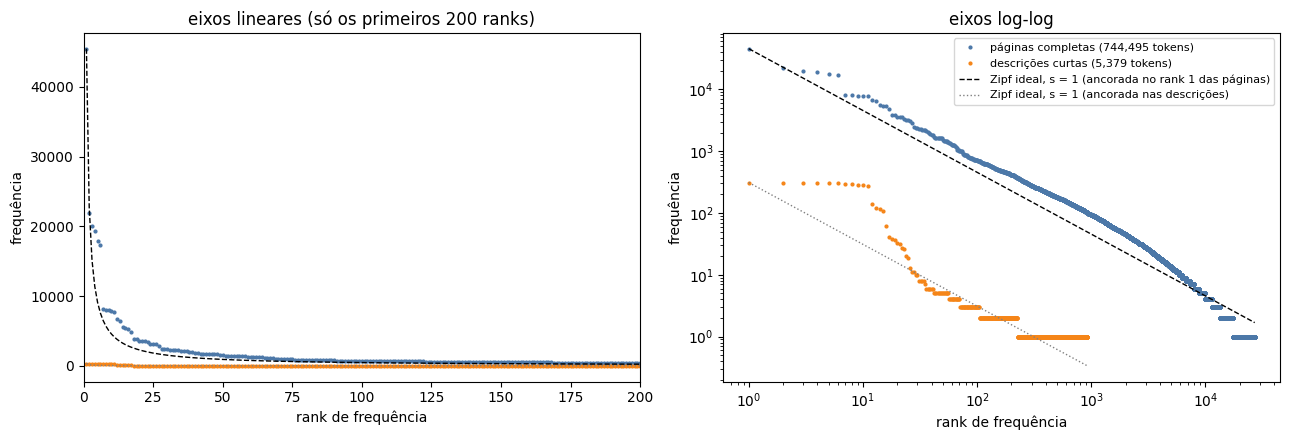

declive local da curva em log-log (Zipf ideal: -1 em todo o lado)
  páginas completas : ranks 1–10: -0.76 | ranks 10–100: -1.07 | ranks 100–1000: -0.89 | ranks 1000–10000: -1.38
  descrições curtas : ranks 1–10: -0.03 | ranks 10–100: -1.75 | ranks 100–1000: -0.35
patamar das descrições — types com contagem entre 280 e 311: ['american', 'appearing', 'books', 'by', 'comic', 'comics', 'in', 'is', 'marvel', 'published']


In [24]:
# 5.4.3 -- frequência vs rank: páginas completas, descrições curtas e a curva ideal
desc_tokens = [w for d in nlp.pipe(nodes.description.fillna("")) for w in toks(d)]
cd = Counter(desc_tokens)
print(f"descrições curtas: {len(desc_tokens):,} tokens, {len(cd):,} types, {np.mean([c == 1 for c in cd.values()]):.0%} hapax; top: {cd.most_common(8)}")

def rank_freq(c):
    f = np.array(sorted(c.values(), reverse=True)); return np.arange(1, len(f) + 1), f
def zipf_slope(c, lo, hi):
    r, f = rank_freq(c); m = (r >= lo) & (r <= min(hi, len(f)))
    return np.polyfit(np.log(r[m]), np.log(f[m]), 1)[0]

rF, fF = rank_freq(counts); rD, fD = rank_freq(cd)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, kind in zip(axes, ["linear", "log"]):
    ax.plot(rF, fF, ".", ms=4, color="#4c78a8", label=f"páginas completas ({n_tokens:,} tokens)")
    ax.plot(rD, fD, ".", ms=4, color="#f58518", label=f"descrições curtas ({len(desc_tokens):,} tokens)")
    ax.plot(rF, fF[0] / rF, "k--", lw=1, label="Zipf ideal, s = 1 (ancorada no rank 1 das páginas)")
    ax.plot(rD, fD[0] / rD, color="gray", ls=":", lw=1, label="Zipf ideal, s = 1 (ancorada nas descrições)")
    ax.set_xlabel("rank de frequência"); ax.set_ylabel("frequência")
    if kind == "log": ax.set_xscale("log"); ax.set_yscale("log"); ax.set_title("eixos log-log")
    else: ax.set_xlim(0, 200); ax.set_title("eixos lineares (só os primeiros 200 ranks)")
axes[1].legend(fontsize=8)
plt.tight_layout(); plt.savefig("figs/5.4_zipf_marvel.png", dpi=150); plt.show()

print("declive local da curva em log-log (Zipf ideal: -1 em todo o lado)")
for lbl, c in [("páginas completas", counts), ("descrições curtas", cd)]:
    segs = [(1, 10), (10, 100), (100, 1000), (1000, 10000)]
    print(f"  {lbl:18s}: " + " | ".join(f"ranks {lo}–{hi}: {zipf_slope(c, lo, hi):+.2f}" for lo, hi in segs if lo < len(c)))
print("patamar das descrições — types com contagem entre 280 e 311:", sorted(w for w, c in cd.items() if 280 <= c <= 311))

**5.4.3 — O corpus maior parece mais Zipf?** Sim, claramente.

- **Descrições curtas** (5 379 tokens, 921 types, 76% hapax): os dez primeiros ranks são um **patamar** —
  *by, marvel, in, is, comics, comic, published, books, appearing, american*, todos entre 286 e 311
  (declive local **−0.03**). Depois a curva cai a pique (−1.75) e termina em degraus.
- **Páginas completas** (744 495 tokens): o declive local anda perto de −1 ao longo de quatro décadas
  (**−0.76**, **−1.07**, **−0.89**, **−1.38**). Nos eixos lineares só se vê uma queda e uma cauda rasa; em
  log-log os mesmos pontos abrem numa reta.

**As explicações do item 1:** as duas continuam plausíveis, e vêem-se na figura. O *tamanho* explica os
degraus e a cauda ruidosa das descrições; o *molde* explica o patamar — as dez palavras do patamar são
literalmente a frase-tipo. A previsão também se confirmou: no corpus grande o topo passa a ser *the, and, of, to*.

**Onde as páginas completas ainda se afastam da reta ideal:** na cabeça a curva é mais plana que −1 (*the*
45 473, *and* 21 936 — metade, como manda Zipf — mas o rank 10, *by*, tem 7 879 em vez dos 4 547 ideais); na
cauda cai mais depressa (−1.38), porque um corpus finito acaba em milhares de palavras empatadas com 1 ocorrência.

### 5.4.4 (🧠) — Uma reta em log-log chega para concluir "Zipf"?

**Não.**

- **O que a figura apoia:** a distribuição tem **cauda pesada** — poucos types concentram a maior parte dos
  tokens e a maioria é rara — e é *aproximadamente* compatível com uma potência inversa do rank na zona em
  que os pontos estão alinhados.
- **O que não estabelece:** que a lei seja *exatamente* Zipf; qual é o expoente (é mesmo $s = 1$? os declives
  locais acima vão de −0.76 a −1.38); em que intervalo de ranks vale; nem que uma lei de potência descreva os
  dados melhor do que outras formas de cauda pesada. Em log-log muitas distribuições parecem retas, e
  desvios grandes parecem pequenos.
- **O que mais verificar:** estimar o expoente e dizer em que ranks; olhar para os desvios na cabeça e na
  cauda; comparar com uma alternativa e com um corpus de referência; repetir com outro pré-processamento e
  com outro tamanho de corpus.

É a lição "is it a power law?" da semana 2, outra vez: a reta é o início da pergunta, não o fim.

Moby Dick: 218,621 tokens, 17,140 types, 44% hapax; top: [('the', 14431), ('of', 6609), ('and', 6430), ('a', 4736), ('to', 4625), ('in', 4172)]


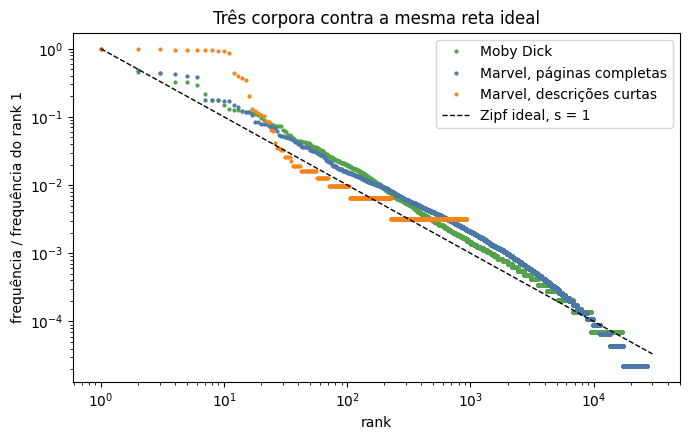

declive local em log-log (Zipf ideal: -1 em todo o lado)
  Moby Dick         : 1–10: -0.77 | 10–100: -0.95 | 100–1000: -1.14 | 1000–10000: -1.19   -> maior afastamento de -1: 0.23
  Marvel completas  : 1–10: -0.76 | 10–100: -1.07 | 100–1000: -0.89 | 1000–10000: -1.38   -> maior afastamento de -1: 0.38
  Marvel descrições : 1–10: -0.03 | 10–100: -1.75 | 100–1000: -0.35   -> maior afastamento de -1: 0.97


In [25]:
# 5.4.5 -- testar a previsão: Moby Dick (amostra Gutenberg do NLTK)
try: nltk.data.find("corpora/gutenberg")
except LookupError: nltk.download("gutenberg", quiet=True)
from nltk.corpus import gutenberg
moby = [w.lower() for w in gutenberg.words("melville-moby_dick.txt") if re.search(r"\w", w)]   # minúsculas, sem pontuação
cm = Counter(moby)
print(f"Moby Dick: {len(moby):,} tokens, {len(cm):,} types, {np.mean([c == 1 for c in cm.values()]):.0%} hapax; top: {cm.most_common(6)}")

fig, ax = plt.subplots(figsize=(7, 4.5))
for lbl, c, col in [("Moby Dick", cm, "#54a24b"), ("Marvel, páginas completas", counts, "#4c78a8"), ("Marvel, descrições curtas", cd, "#f58518")]:
    r, f = rank_freq(c); ax.loglog(r, f / f[0], ".", ms=4, color=col, label=lbl)     # normalizado pelo rank 1
r = np.arange(1, 30000); ax.loglog(r, 1 / r, "k--", lw=1, label="Zipf ideal, s = 1")
ax.set_xlabel("rank"); ax.set_ylabel("frequência / frequência do rank 1"); ax.legend()
ax.set_title("Três corpora contra a mesma reta ideal")
plt.tight_layout(); plt.savefig("figs/5.4_zipf_three_corpora.png", dpi=150); plt.show()

print("declive local em log-log (Zipf ideal: -1 em todo o lado)")
for lbl, c in [("Moby Dick", cm), ("Marvel completas", counts), ("Marvel descrições", cd)]:
    segs = [(1, 10), (10, 100), (100, 1000), (1000, 10000)]
    sl = [zipf_slope(c, lo, hi) for lo, hi in segs if lo < len(c)]
    print(f"  {lbl:18s}: " + " | ".join(f"{lo}–{hi}: {v:+.2f}" for (lo, hi), v in zip(segs, sl))
          + f"   -> maior afastamento de -1: {max(abs(v + 1) for v in sl):.2f}")

### 5.4.5 (🧠) — Mais Zipf e menos Zipf

- **Mais Zipf:** um texto longo, contínuo, de um só autor e em prosa natural — ***Moby Dick***. É grande e
  ninguém lhe impôs um molde.
- **Menos Zipf:** texto curto, repetitivo ou em lista — as próprias **descrições curtas** da Marvel, um
  catálogo de produtos, boletins meteorológicos, uma tabela de resultados desportivos. Um conjunto fixo de
  palavras repete-se com frequência quase igual (cabeça plana) e há pouco vocabulário livre (cauda curta).

**Teste.** *Moby Dick* (218 621 tokens, 17 140 types): declives locais **−0.77, −0.95, −1.14, −1.19** — o
maior afastamento de −1 é 0.23. Nas páginas Marvel completas é 0.38, e nas descrições curtas 0.97.
A previsão confirma-se nos dois sentidos — e *Moby Dick* é mais Zipf do que a Marvel **apesar de ter 3.4
vezes menos tokens**: o tamanho ajuda, mas o tipo de texto pesa mais.

## Exercício 5.5 — Context and local order (🧠 learn + 🔬 tool)

> Counts tell us what is common. Here we ask what the surrounding language adds.
>
> 1. 🔬 Choose one word that occurs often enough in the Marvel corpus to be interesting and has more than one plausible use. Make a concordance for it and run NLTK's `similar()`. Explain, in your own words, the question each output answers. Inspect the original text before deciding whether the returned words actually have similar meanings.
> 2. Count the most common bigrams and trigrams. Pick one of each and find the exact passage it came from. What information did the bigram or trigram retain that unigram counts would have thrown away?
> 3. Rank bigrams once by raw frequency and once with an association measure such as likelihood ratio or PMI. Find one pair that looks important under raw frequency and one that becomes interesting only after association scoring. Why did the ranking move?
> 4. 🧠 Write two short sentences that have the same unigram counts but different word order. Show that their unigram representation is identical, then show one bigram that tells them apart.
> 5. 🔬 Verify one unigram count, one bigram count and one concordance hit directly in the raw text. If the code and the text disagree, the text wins. Work out what happened.
> 6. 🧠 Rewrite the AI-drafted report above in three honest sentences: what was counted, what it was compared against, and what the counts do and do not establish about Marvel.

### Exemplo do texto (secção 3, *Python example: concordance*)

O código da página, tal como está, com *power*. Usa o `marvel_tokens` do pipeline do 5.3. As três saídas
respondem a perguntas diferentes:

- `concordance` mostra **a própria palavra**, em cada ocorrência, com a vizinhança.
- `similar` mostra **outras palavras** que aparecem nos mesmos contextos (palavra antes, palavra depois).
- `common_contexts` mostra **que contextos** duas palavras partilham.

In [26]:
from nltk.text import Text

marvel = Text(marvel_tokens)

marvel.concordance("power")
marvel.similar("power")
marvel.common_contexts(["power", "strength"])

Displaying 25 of 820 matches:
 superhuman levels it leaves blonsky power hungry and eventually drives him to 
he story continued in the series the power of warlock which ran eight issues au
title continued the numbering of the power of warlock and began with warlock 9 
sitive zone searching for an immense power source that turns out to be adam him
ed by gladiator also looking for the power source appear and annihilus now with
ce appear and annihilus now with the power of the hulk and a new fear projectio
 a part of him and has given him the power of eternity and infinity thanos enha
dam is placed into annihilus ship 's power source to use him as battery pip aft
utilizing the available energies and power in his surroundings as well as emplo
em adam warlock has demonstrated the power to devolve the followers of man beas
ges them into a cosmic egg using its power she recreates counter earth dubbing 
ver twenty five years to gain enough power to destroy earth and restore it to t
masters al

In [27]:
# 5.5.1 -- concordância e similar() para "vision"
marvel = Text(marvel_tokens)
WORD = "vision"
marvel.concordance(WORD, width=92, lines=12)
print()
marvel.similar(WORD, 15)
print()
marvel.common_contexts([WORD, "power"])

Displaying 12 of 191 matches:
s are once more being gathered and shows a vision of the future which kang calls infinity 's
 simone and udon to complete their initial vision as part of a three issue arc tying up the 
r with cat like abilities giving her night vision retractable talons in her fingertips super
 wakanda and articulated a more democratic vision the black panther is the first black super
ar todd steven burroughs describes the new vision for the black panther as a combination of 
to portray a more democratic and inclusive vision of african nationalism coates and gay also
t the fin and the golden age angel and the vision i to aid the superhero team the avengers i
ar ii storyline ulysses cain experiences a vision that warns blue marvel about the impending
embers join the team brian has a prophetic vision concerning the london branch of the hellfi
traordinary sight with enhanced peripheral vision gained by wearing his helmet his antennae 
gible at will see through substances x r

In [28]:
# ler o texto original antes de acreditar: que "vision" é cada uma das ocorrências?
# (aqui a capitalização ajuda — é exatamente a informação que o lowercase deitou fora)
hits = []
for i in IDS:
    for m in re.finditer(r"\b[Vv]ision\b", marvel_pages[i]):
        s = marvel_pages[i]; a, b = max(0, m.start() - 45), min(len(s), m.end() + 45)
        hits.append((i, m.group(), s[a:b].replace("\n", " ")))
print(f"{len(hits)} ocorrências em bruto: {sum(h[1] == 'Vision' for h in hits)} 'Vision' e {sum(h[1] == 'vision' for h in hits)} 'vision'")
print("páginas com mais ocorrências:", Counter(h[0] for h in hits).most_common(4))
low_ctx = Counter(re.search(r"(\w+)[ -]vision", h[2]).group(1).lower() for h in hits if h[1] == "vision" and re.search(r"(\w+)[ -]vision", h[2]))
print("palavra antes de 'vision' (minúscula):", low_ctx.most_common(8))
for h in [hits[k] for k in (0, 5, 60, 120)]:
    print(f"  [{h[0][:22]:22s}] …{h[2]}…")

# e as palavras que o similar() devolveu: são "parecidas" em quê?
for w in ["character", "team", "hulk"]:
    print(f"\ncontextos partilhados por 'vision' e '{w}': ", end=""); marvel.common_contexts([WORD, w], 8)

191 ocorrências em bruto: 131 'Vision' e 60 'vision'
páginas com mais ocorrências: [('Scarlet_Witch', 61), ('Speed_(character)', 13), ('Human_Torch_(android)', 11), ('Hercules_(Marvel_Comics)', 6)]
palavra antes de 'vision' (minúscula): [('a', 23), ('night', 7), ('telescopic', 3), ('his', 2), ('of', 2), ('her', 2), ('initial', 1), ('democratic', 1)]
  [Adam_Warlock          ] …nes are once more being gathered and shows a vision of the future – which Kang calls "Infinity's…
  [Black_Panther_(charact] …e to portray a more democratic and inclusive vision of African nationalism. Coates and Gay also …
  [Iron_Lad              ] …splits into Iron Lad (Nate) and the original Vision. Iron Lad appears to maintain the memories o…
  [Scarlet_Witch         ] …twin. The US government insists on confining Vision and studying him so he can't be taken over b…

contextos partilhados por 'vision' e 'character': a_of the_and the_in the_is a_that the_while the_as the_was

contextos partilhados por 'vision

**5.5.1 — A palavra: *vision*** (191 ocorrências).

**Que pergunta responde cada saída:**

- **`concordance("vision")`** — *"como é que esta palavra é usada aqui?"* Mostra **a própria palavra**, em
  cada ocorrência, com a vizinhança. Em doze linhas já se vêem quatro usos: uma visão do futuro (*shows a
  vision of the future*, *a prophetic vision*), uma conceção (*a more democratic vision*, *initial vision*),
  a capacidade de ver (*night vision*, *x ray vision*, *peripheral vision*) e a personagem (*the vision*).
- **`similar("vision")`** — *"que outras palavras aparecem nos mesmos sítios?"* Não mostra *vision*: devolve
  **palavras diferentes** que partilham os contextos imediatos (a palavra antes e a palavra depois).

**O texto original, antes de acreditar.** Das 191 ocorrências, **131 são `Vision`** (a personagem — 61 delas
na página da Scarlet Witch) e **60 são `vision`**; destas, 23 vêm depois de *a* e 7 depois de *night*.

**As palavras devolvidas têm significado parecido? Não.** `similar()` devolveu *character, team, hulk, time,
series, story, avengers, book, hero, group, symbiote…* — nenhuma é sinónimo de *vision*. Os contextos
partilhados explicam porquê: são moldes como **the _ of**, **the _ and**, **a _ of**, **the _ is** — o lugar
de **um substantivo qualquer** depois de um artigo. E *hulk* partilha **the _ and**, **the _ is**: o contexto
de *nome de personagem*, que é o uso dominante de *Vision* neste corpus. O método encontrou a classe
gramatical e a personagem, não o significado — "contexto parecido" não é "significado parecido".

In [29]:
# 5.5.2 -- bigramas e trigramas mais comuns
bi = Counter(ngrams(marvel_tokens, 2)); tri = Counter(ngrams(marvel_tokens, 3))
print(f"{sum(bi.values()):,} bigramas ({len(bi):,} distintos; {np.mean([c == 1 for c in bi.values()]):.0%} ocorrem 1×)")
print(f"{sum(tri.values()):,} trigramas ({len(tri):,} distintos; {np.mean([c == 1 for c in tri.values()]):.0%} ocorrem 1×)")
print(f"(unigramas: {n_types:,} distintos; {len(hapax) / n_types:.0%} ocorrem 1×)\n")
print("top 12 bigramas :", [(" ".join(g), c) for g, c in bi.most_common(12)])
print("top 12 trigramas:", [(" ".join(g), c) for g, c in tri.most_common(12)])

# a passagem exata de um bigrama e de um trigrama
for pat in [r"[^.\n]*\bNew York\b[^.\n]*", r"[^.\n]*playable character in[^.\n]*"]:
    pid, m = next((i, re.search(pat, marvel_pages[i])) for i in IDS if re.search(pat, marvel_pages[i]))
    print(f"\n[{pid}] {m.group().strip()[:260]}")
print("\nunigramas:", {w: counts[w] for w in ["new", "york", "playable", "character", "in"]})
print("o que segue 'new':", Counter(b for (a, b), c in bi.items() if a == "new" for _ in range(c)).most_common(6))

744,494 bigramas (281,132 distintos; 74% ocorrem 1×)
744,493 trigramas (541,960 distintos; 88% ocorrem 1×)
(unigramas: 26,987 distintos; 36% ocorrem 1×)

top 12 bigramas : [('of the', 5932), ('in the', 4681), ('as a', 2312), ('spider man', 1933), ('to the', 1848), ('and the', 1720), ('with the', 1538), ('x men', 1501), ('the character', 1297), ('by the', 1246), ('appears in', 1158), ('is a', 1121)]
top 12 trigramas: [('the x men', 611), ('appears as a', 541), ('playable character in', 509), ('a member of', 495), ('member of the', 478), ('one of the', 431), ('appears in the', 389), ('as a playable', 384), ('a playable character', 384), ('character in marvel', 380), ('the marvel universe', 332), ('published by marvel', 324)]

[Abomination_(character)] The Abomination captures her and after taking her into the New York City sewers, reveals his true identity

[Abomination_(character)] The Emil Blonsky incarnation of the Abomination appears as the final boss of and an unlockable playable ch

**5.5.2 — Bigramas e trigramas.** O topo dos bigramas é gramática (*of the* 5 932, *in the* 4 681, *as a*) com
dois nomes partidos pelo hífen (*spider man* 1 933, *x men* 1 501). O topo dos trigramas é o molde da
Wikipédia: *appears as a*, *playable character in*, *a member of*, *published by marvel*.

**A esparsidade vê-se nos números:** 36% dos unigramas distintos ocorrem uma só vez, **74%** dos bigramas e
**88%** dos trigramas. Mais contexto, contagens cada vez mais finas.

**O bigrama *new york* (255).** Passagem (página de Abomination): *"…after taking her into the New York City
sewers…"*. O que o bigrama guardou: a **adjacência e a ordem**. Os unigramas dizem só que *new* ocorre 2 270
vezes e *york* 256; o bigrama diz que *york* vem a seguir a *new* em **255 das 256** vezes — é um nome, não
duas palavras. E mostra que *new* tem outros usos: *new warriors* 115, *new avengers* 112, *new mutants* 109.

**O trigrama *playable character in* (509).** Passagem: *"…appears as the final boss of and an unlockable
playable character in The Incredible Hulk: Ultimate Destruction, voiced by Ron Perlman"*. As contagens de
*playable* (565), *character* (3 176) e *in* (17 885) nunca revelariam isto: quase todas as páginas têm
uma secção de videojogos escrita com a mesma frase feita. O trigrama apanhou o molde.

### Exemplo do texto (secção 3, *collocations*)

O código da página, tal como está: bigramas com pelo menos 5 ocorrências, ordenados por *likelihood ratio*.
O 5.5.3 a seguir faz o mesmo e compara com a frequência bruta e com o PMI.

In [30]:
from nltk.collocations import BigramCollocationFinder, BigramAssocMeasures

finder = BigramCollocationFinder.from_words(marvel_tokens)
finder.apply_freq_filter(5)

finder.nbest(
    BigramAssocMeasures().likelihood_ratio,
    10
)

[('x', 'men'),
 ('spider', 'man'),
 ('of', 'the'),
 ('as', 'a'),
 ('captain', 'america'),
 ('in', 'the'),
 ('comic', 'book'),
 ('ghost', 'rider'),
 ('appears', 'in'),
 ('playable', 'character')]

In [31]:
# 5.5.3 -- frequência bruta vs medidas de associação
finder = BigramCollocationFinder.from_words(marvel_tokens)
finder.apply_freq_filter(5)
M = BigramAssocMeasures()
lr_scored = finder.score_ngrams(M.likelihood_ratio); lr_rank = {g: k + 1 for k, (g, _) in enumerate(lr_scored)}
raw_rank = {g: k + 1 for k, (g, _) in enumerate(bi.most_common())}
print("top 12 por likelihood ratio:", [" ".join(g) for g, _ in lr_scored[:12]])
print("top 12 por PMI (freq ≥ 5)  :", [" ".join(g) for g in finder.nbest(M.pmi, 12)])
f20 = BigramCollocationFinder.from_words(marvel_tokens); f20.apply_freq_filter(20)
print("top 12 por PMI (freq ≥ 20) :", [" ".join(g) for g in f20.nbest(M.pmi, 12)])

rows = []
for g in [("of", "the"), ("in", "the"), ("the", "character"), ("spider", "man"), ("x", "men"), ("captain", "america"),
          ("fantastic", "four"), ("new", "york"), ("doctor", "strange"), ("fin", "fang")]:
    a, b = g; exp = counts[a] * counts[b] / n_tokens
    rows.append(dict(bigrama=" ".join(g), n=bi[g], n_a=counts[a], n_b=counts[b], esperado=round(exp, 1),
                     obs_sobre_esp=round(bi[g] / exp, 1), PMI=round(np.log2(bi[g] / exp), 2),
                     rank_bruto=raw_rank[g], rank_LR=lr_rank[g]))
print("\n" + pd.DataFrame(rows).to_string(index=False))

top 12 por likelihood ratio: ['x men', 'spider man', 'of the', 'as a', 'captain america', 'in the', 'comic book', 'ghost rider', 'appears in', 'playable character', 'marvel comics', 'to be']
top 12 por PMI (freq ≥ 5)  : ['jb blanc', 'kavita rao', 'nintendo ds', 'rama tut', 'avi arad', 'gah lak', 'kathreen khavari', 'lak tus', 'leonardo manco', 'quinton flynn', 'zarina zahari', 'arnim zola']
top 12 por PMI (freq ≥ 20) : ['tel kar', 'trevor devall', 'shou lao', 'mahr vehl', 'le fay', 'los angeles', 'ka zar', 'b. gillis', 'kamala khan', 'jesse schedeen', 'mys tech', 'alexei shostakov']

        bigrama    n   n_a   n_b  esperado  obs_sobre_esp   PMI  rank_bruto  rank_LR
         of the 5932 20011 45473    1222.3            4.9  2.28           1        3
         in the 4681 17885 45473    1092.4            4.3  2.10           2        6
  the character 1297 45473  3176     194.0            6.7  2.74           9       37
     spider man 1933  3373  3544      16.1          120.4  6.91      

**5.5.3 — Frequência bruta contra associação.**

O cálculo para *x men*, à mão ($N = 744\,495$ tokens):
$$
\text{esperado por acaso} = \frac{n_x \cdot n_{men}}{N} = \frac{2\,234 \cdot 1\,630}{744\,495} = 4.9
$$
$$
\frac{\text{observado}}{\text{esperado}} = \frac{1\,501}{4.9} \approx 307
$$
$$
\mathrm{PMI} = \log_2 307 = 8.26
$$

- **Parece importante pela frequência bruta:** *the character* — 9.º por contagem (1 297). Mas *the* é tão
  frequente que 194 dessas ocorrências já eram esperadas por acaso (observado/esperado = 6.7, PMI 2.74): cai
  para **37.º** por *likelihood ratio*. *of the* e *in the* têm PMI ainda mais baixo (2.3 e 2.1).
- **Só fica interessante com a medida de associação:** *captain america* — 38.º por contagem, **5.º** por LR
  (515 vezes mais do que o acaso). *fantastic four* sobe de 111.º para 17.º; *fin fang* (de Fin Fang Foom), com
  só 56 ocorrências, tem PMI 13.6: as duas palavras quase nunca aparecem separadas.

**Porque é que o ranking se mexe:** as duas listas fazem perguntas diferentes. A contagem pergunta *"quantas
vezes juntas?"*; a associação pergunta *"quantas vezes mais do que as frequências separadas preveem?"*.

**As duas medidas também não concordam entre si.** A *likelihood ratio* mede a **evidência** contra a
independência e cresce com o número de observações — por isso *of the* continua em 3.º. O PMI mede só a
**razão** e favorece pares raros: o topo por PMI são nomes de atores de voz e de produtores (*jb blanc*,
*quinton flynn*, *avi arad*). Daí o filtro de frequência: sem ele, o topo do PMI seriam pares vistos uma vez.

### 5.5.4 (🧠) — Mesmos unigramas, ordem diferente

- **A** = *the dog chased the ball*
- **B** = *the ball chased the dog*

Contagens de unigramas, em A e em B: *the* 2 · *dog* 1 · *chased* 1 · *ball* 1 — **idênticas**.

Bigramas de A: *the dog*, **dog chased**, *chased the*, *the ball*.
Bigramas de B: *the ball*, **ball chased**, *chased the*, *the dog*.

*dog chased* só existe em A (e *ball chased* só em B): um bigrama chega para as distinguir.

In [32]:
# Verificação do 5.5.4
A = "the dog chased the ball".split(); B = "the ball chased the dog".split()
print("unigramas iguais?", Counter(A) == Counter(B), dict(Counter(A)))
bA, bB = set(ngrams(A, 2)), set(ngrams(B, 2))
print("bigramas só em A:", sorted(bA - bB), "| só em B:", sorted(bB - bA), "| comuns:", sorted(bA & bB))

unigramas iguais? True {'the': 2, 'dog': 1, 'chased': 1, 'ball': 1}
bigramas só em A: [('dog', 'chased')] | só em B: [('ball', 'chased')] | comuns: [('chased', 'the'), ('the', 'ball'), ('the', 'dog')]


In [33]:
# 5.5.5 -- conferir o código contra o texto em bruto (o texto ganha)
ALL = "\n".join(marvel_pages[i] for i in IDS)

# (1) um unigrama
n_code = counts["vision"]; n_text = len(re.findall(r"\bvision\b", ALL, flags=re.I))
print(f"unigrama 'vision':  código {n_code}  |  texto (regex \\bvision\\b, sem distinguir maiúsculas) {n_text}")

# (2) um bigrama
n_code = bi[("new", "york")]
n_text = len(re.findall(r"\bnew york\b", ALL, flags=re.I)); n_text_ws = len(re.findall(r"\bnew\s+york\b", ALL, flags=re.I))
print(f"bigrama 'new york': código {n_code}  |  texto 'new york' {n_text}  |  com qualquer espaço/newline no meio {n_text_ws}")

# (3) um bigrama em que o código e o texto discordam
n_code = bi[("spider", "man")]
print(f"bigrama 'spider man': código {n_code}  |  texto 'spider man' (com espaço) {len(re.findall(r'spider man', ALL, flags=re.I))}"
      f"  |  texto 'Spider-Man' (com hífen) {len(re.findall(r'spider-man', ALL, flags=re.I))}")
print(f"   …e o trigrama 'spider - man' não existe porque a pontuação foi removida: {tri[('spider', '-', 'man')]}")
print("   formas no texto:", Counter(re.findall(r"spider.?man\w*", ALL, flags=re.I)).most_common(6))

# (4) um hit da concordância, localizado no texto original
pos = [(i, t.idx) for i in IDS for t in docs[i] if not (t.is_space or t.is_punct)]     # paralelo a marvel_tokens
k = marvel_tokens.index("vision"); pid, idx = pos[k]
print(f"\n1º hit de 'vision': token nº {k:,} do corpus -> página '{pid}', carácter {idx}")
print("   concordância:", " ".join(marvel_tokens[k - 8:k + 9]))
print("   texto bruto :", repr(marvel_pages[pid][idx - 48:idx + 50]))

unigrama 'vision':  código 191  |  texto (regex \bvision\b, sem distinguir maiúsculas) 191
bigrama 'new york': código 255  |  texto 'new york' 255  |  com qualquer espaço/newline no meio 255
bigrama 'spider man': código 1933  |  texto 'spider man' (com espaço) 2  |  texto 'Spider-Man' (com hífen) 1932
   …e o trigrama 'spider - man' não existe porque a pontuação foi removida: 0
   formas no texto: [('Spider-Man', 1932), ('Spider manages', 1), ('Spider Man', 1)]

1º hit de 'vision': token nº 7,640 do corpus -> página 'Adam_Warlock', carácter 21574
   concordância: are once more being gathered and shows a vision of the future which kang calls infinity 's
   texto bruto : 'Stones are once more being gathered and shows a vision of the future – which Kang calls "Infinity\''


**5.5.5 — O código contra o texto em bruto.**

- **Unigrama *vision*:** código 191, texto 191. ✓
- **Bigrama *new york*:** código 255, texto 255. ✓
- **Hit da concordância:** o primeiro *vision* é o token n.º 7 640 do corpus → página de Adam Warlock; o
  texto em bruto diz *"…and shows a vision of the future – which Kang calls "Infinity's…"* — a mesma passagem,
  com a pontuação e as maiúsculas que o pipeline tirou. ✓
- **Onde código e texto discordam — *spider man*:** o código conta **1 933** bigramas; no texto, a sequência
  "spider man" com um espaço aparece **2 vezes**. O que aconteceu: o texto diz ***Spider-Man*** com hífen
  (1 932 vezes); o spaCy partiu no hífen e eu removi a pontuação, o que deixou *spider* e *man* lado a lado.
  O bigrama mais frequente de conteúdo do corpus é fabricado pelo pré-processamento. **O texto ganha:** é um
  nome só, e a contagem honesta é "1 932 menções a Spider-Man".

### 5.5.6 (🧠) — O relatório do AI, reescrito

> "The Marvel corpus is dominated by the language of publishing rather than heroism: the most frequent words are *the, of, Marvel, Comics* and *published*. Frequency against rank is a straight line on log-log axes, which proves the corpus follows Zipf's law. And *power* occurs 1,204 times, making it the central theme of the Marvel universe."

**As três falhas:** (1) uma lista de frequências apresentada como descoberta — *the* e *of* estão no topo de
qualquer texto em inglês, e *Marvel / Comics / published* são a frase de abertura da Wikipédia; não se comparou
com nada; (2) uma reta em log-log apresentada como prova; (3) uma contagem bruta apresentada como
significado. (E uma quarta, da mesma família: o pré-processamento nunca é dito.)

**Três frases honestas:**

1. *Contámos as frequências das palavras nas 303 páginas Marvel da Wikipédia (744 495 tokens; tokens do spaCy,
   minúsculas, sem pontuação, stopwords mantidas): as mais frequentes são* the, and, of, to, in *— como em
   qualquer texto em inglês — e, entre as de conteúdo,* marvel, character, series *e* appears, *que vêm das
   frases feitas da Wikipédia.*
2. *Comparámos a curva frequência–rank com uma reta de Zipf ideal: em log-log é aproximadamente reta (declive
   local entre −0.8 e −1.4), o que é compatível com um padrão do tipo Zipf mas não o prova; não comparámos a
   lista de palavras com nenhum outro corpus.*
3. *Com este pré-processamento,* power *ocorre 820 vezes (0.11% dos tokens) e* powers *1 456; estas contagens
   não mostram como a palavra é usada nem que seja um tema central — 271 das ocorrências de* powers *são o
   título de secção "Powers and abilities" — e seria preciso um corpus de referência e uma concordância para dizer mais.*

(Nota: os 1 204 do relatório não saem de nenhuma das contagens deste notebook — 820 para *power*, 595 só em
minúscula, 1 456 para *powers*. Mais uma razão para exigir o pré-processamento por escrito.)

## Exercício 5.6 — Bag of Words, by hand (🧠 learn)

> No library for this one. If you can build the tiny matrix yourself, the large one stops being mysterious.
>
> 1. Use the three documents *Thor fights the X-Men.*, *The X-Men fight back.* and *Thor and Loki fight and fight.* Lowercase everything, drop the punctuation, and keep *X-Men* as one word. Alphabetize the vocabulary, write the three document vectors, and stack them into the document-term matrix.
> 2. Read the matrix in both directions. Which terms do Documents 1 and 2 share? Which terms connect Document 3 to the other two? Pick the column for *fight* and explain what every number in that column means. Why do *fight* and *fights* get separate columns, and which preprocessing step from Section 2 would merge them?
> 3. Change one document so that a word already in the vocabulary appears one more time, and another so that it contains a brand-new word. Predict exactly which cells change, and what happens to the shape of the matrix, before you recalculate it.
> 4. Give one research question where losing word order is probably acceptable and one where it would make the representation close to useless.

### 5.6.1 — Pré-processar, vocabulário, vetores

**Passo 1 — minúsculas, sem pontuação, *x-men* inteiro:**

- D1: *thor fights the x-men*
- D2: *the x-men fight back*
- D3: *thor and loki fight and fight*

**Passo 2 — vocabulário por ordem alfabética (8 termos):** *and, back, fight, fights, loki, the, thor, x-men*

**Passo 3 — percorrer o vocabulário termo a termo, para cada documento:**

| | and | back | fight | fights | loki | the | thor | x-men |
|---|---:|---:|---:|---:|---:|---:|---:|---:|
| **D1** | 0 | 0 | 0 | 1 | 0 | 1 | 1 | 1 |
| **D2** | 0 | 1 | 1 | 0 | 0 | 1 | 0 | 1 |
| **D3** | 2 | 0 | 2 | 0 | 1 | 0 | 1 | 0 |

**Verificação — a soma de cada linha é o comprimento do documento:** $4,\ 4,\ 6$ ✓ (D3: $2+2+1+1 = 6$).
Forma $3 \times 8$; 12 das 24 células são zero (50%).

### 5.6.2 — Ler nos dois sentidos

- **Por linhas.** D1 e D2 partilham **the** e **x-men** (as duas colunas com 1 nas duas linhas). D3 liga-se a
  D1 só por **thor**, e a D2 só por **fight**.
- **Coluna *fight*** $= (0,\ 1,\ 2)$: D1 não tem a forma *fight* (tem *fights*); D2 tem-na uma vez; D3 duas vezes.
- ***fight* vs *fights*:** o Bag of Words dá uma coluna por **string distinta**, e são dois types diferentes.
  A **lematização** (*fights* → *fight*) funde-as: a coluna *fights* desaparece, a coluna *fight* passa a
  $(1,\ 1,\ 2)$, a matriz encolhe para $3 \times 7$ — e D1 passa a partilhar *fight* com os outros dois.

### 5.6.3 — Prever, depois recalcular

- **Uma palavra que já existe, mais uma vez:** D2 → *The X-Men fight **Thor** back.* Muda **uma** célula:
  (D2, *thor*) de 0 para 1. A forma continua $3 \times 8$.
- **Uma palavra nova:** D1 → *Thor fights the X-Men **today**.* Aparece uma **coluna nova**, *today*
  (alfabeticamente entre *thor* e *x-men*), com valores $(1,\ 0,\ 0)$. A forma passa a $3 \times 9$. Nenhuma
  contagem antiga muda, mas **todos** os documentos ganham uma coordenada — D2 e D3 ganham um zero.

**Regra:** mais uma ocorrência de uma palavra conhecida muda uma célula; uma palavra nova acrescenta uma
coluna a todos os documentos. É por isso que as matrizes reais são tão largas e tão esparsas.

### 5.6.4 — Quando perder a ordem importa

- **Aceitável:** *"que páginas Marvel falam de coisas parecidas?"* ou *"de que fala a comunidade A que a B não
  fala?"* — o tema está em que palavras ocorrem e quantas vezes.
- **Quase inútil:** *"quem derrotou quem?"* — *Thor defeats Loki* e *Loki defeats Thor* têm o mesmo vetor
  (verificado no 5.7.5). O mesmo para a negação e para qualquer pergunta sobre quem fez o quê a quem.

In [40]:
# Verificação do 5.6 -- a matriz construída "à mão" em código, sem biblioteca
DOCS = ["Thor fights the X-Men.", "The X-Men fight back.", "Thor and Loki fight and fight."]
def my_tokens(s):                       # minúsculas, sem pontuação, X-Men fica uma palavra
    return re.findall(r"[a-z]+(?:-[a-z]+)*", s.lower())
tok56 = [my_tokens(s) for s in DOCS]
vocab = sorted(set(w for t in tok56 for w in t))
X_hand = pd.DataFrame([[t.count(w) for w in vocab] for t in tok56], columns=vocab, index=["D1", "D2", "D3"])
print(X_hand.to_string())
print(f"\nforma {X_hand.shape}, zeros: {(X_hand.values == 0).sum()} de {X_hand.size} ({(X_hand.values == 0).mean():.0%}); somas das linhas {X_hand.sum(axis=1).tolist()}")

# 5.6.2: lematizar funde fight/fights
lem = [[t.lemma_.lower() for t in nlp(" ".join(tk))] for tk in tok56]
print("\ncom lematização:", [" ".join(l) for l in lem])
# 5.6.3: as duas alterações
def dtm(texts):
    tk = [my_tokens(s) for s in texts]; v = sorted(set(w for t in tk for w in t))
    return pd.DataFrame([[t.count(w) for w in v] for t in tk], columns=v, index=["D1", "D2", "D3"])
X2 = dtm(["Thor fights the X-Men today.", "The X-Men fight Thor back.", DOCS[2]])
print("\ndepois das duas alterações:\n" + X2.to_string(), "\nforma", X2.shape)

    and  back  fight  fights  loki  the  thor  x-men
D1    0     0      0       1     0    1     1      1
D2    0     1      1       0     0    1     0      1
D3    2     0      2       0     1    0     1      0

forma (3, 8), zeros: 12 de 24 (50%); somas das linhas [4, 4, 6]

com lematização: ['thor fight the x - man', 'the x - man fight back', 'thor and loki fight and fight']

depois das duas alterações:
    and  back  fight  fights  loki  the  thor  today  x-men
D1    0     0      0       1     0    1     1      1      1
D2    0     1      1       0     0    1     1      0      1
D3    2     0      2       0     1    0     1      0      0 
forma (3, 9)


## Exercício 5.7 — Bag of Words on Marvel, as code (🔬 tool)

> Now scale the same object up. The agent may write the code; you still have to know what its matrix means.
>
> 1. Reproduce your three-document matrix from 5.6 with scikit-learn's `CountVectorizer`. Compare every column and every cell with your hand-built version. Something will differ. Find the preprocessing choice inside `CountVectorizer` that caused it.
> 2. Apply the same operation to the full Marvel pages, one page per document. Report the matrix shape, the five longest documents (in tokens), the five most frequent vocabulary terms and the proportion of matrix cells that are zero. Your vocabulary will probably not be the 27,000 terms quoted in the text above. Explain why.
> 3. Pick one vocabulary column and trace it back to the documents. Which pages have the largest counts for that term? Open at least two of those pages and check that the counts make sense in context.
> 4. Change exactly one preprocessing choice, for example lowercasing, stopword removal, lemmatization, or dropping terms that occur in only one document. Rebuild the matrix and report what changed in its shape, sparsity and most common terms. Explain the change rather than just printing the numbers.
> 5. Finish with one paragraph: what can this matrix answer about the corpus already, and what question would force you to move beyond Bag of Words?

In [35]:
# 5.7.1 -- o mesmo com o CountVectorizer
vec = CountVectorizer()
X_sk = pd.DataFrame(vec.fit_transform(DOCS).toarray(), columns=vec.get_feature_names_out(), index=["D1", "D2", "D3"])
print("CountVectorizer() por omissão:\n" + X_sk.to_string())
print("\ncolunas só à mão:", sorted(set(X_hand.columns) - set(X_sk.columns)), "| só no sklearn:", sorted(set(X_sk.columns) - set(X_hand.columns)))
print("token_pattern por omissão:", repr(vec.token_pattern), "| lowercase =", vec.lowercase)
print("o analisador por omissão em 'Thor fights the X-Men.':", vec.build_analyzer()("Thor fights the X-Men."))

# corrigir: dizer ao CountVectorizer o que é uma palavra
vec2 = CountVectorizer(token_pattern=r"(?u)\b\w+(?:-\w+)*\b")
X_fix = pd.DataFrame(vec2.fit_transform(DOCS).toarray(), columns=vec2.get_feature_names_out(), index=["D1", "D2", "D3"])
print("\ncom token_pattern que aceita hífenes: igual à matriz feita à mão?", X_fix.equals(X_hand.astype(X_fix.dtypes.iloc[0])))

CountVectorizer() por omissão:
    and  back  fight  fights  loki  men  the  thor
D1    0     0      0       1     0    1    1     1
D2    0     1      1       0     0    1    1     0
D3    2     0      2       0     1    0    0     1

colunas só à mão: ['x-men'] | só no sklearn: ['men']
token_pattern por omissão: '(?u)\\b\\w\\w+\\b' | lowercase = True
o analisador por omissão em 'Thor fights the X-Men.': ['thor', 'fights', 'the', 'men']

com token_pattern que aceita hífenes: igual à matriz feita à mão? True


**5.7.1 — O que difere.** Continuam 8 colunas, mas a coluna **`x-men` passou a `men`** (e a ordem alfabética
mudou com ela). Todas as outras células são iguais.

**A causa:** o `token_pattern` por omissão, `(?u)\b\w\w+\b` — um token é uma sequência de **duas ou mais**
letras/dígitos. O hífen não é letra, por isso *X-Men* parte-se em *x* e *men*; e *x*, com uma letra só, é
**descartado em silêncio**. (As outras duas escolhas escondidas — `lowercase=True` e deitar fora a pontuação —
coincidem com as do 5.6, por isso não se notam.) Com um padrão que aceita hífenes a matriz fica igual à feita à mão.

In [36]:
# 5.7.2 -- as 303 páginas, uma página por documento
texts = [marvel_pages[i] for i in IDS]
cv = CountVectorizer()
X = cv.fit_transform(texts)                      # matriz esparsa (scipy CSR)
terms = cv.get_feature_names_out()
doc_len = np.asarray(X.sum(1)).ravel(); term_tot = np.asarray(X.sum(0)).ravel()
print(f"forma: {X.shape}  ({X.shape[0]} documentos × {X.shape[1]:,} termos)")
print(f"células: {X.shape[0] * X.shape[1]:,}; não nulas: {X.nnz:,}; proporção de zeros: {1 - X.nnz / (X.shape[0] * X.shape[1]):.2%}")
distinct = np.asarray((X > 0).sum(1)).ravel()
print(f"total de contagens (tokens): {X.sum():,}; termos distintos por página: mediana {int(np.median(distinct))} "
      f"(= {np.median(distinct) / X.shape[1]:.1%} do vocabulário)")
print("5 documentos mais longos:", [(name[IDS[j]], int(doc_len[j])) for j in doc_len.argsort()[::-1][:5]])
print("5 mais curtos           :", [(name[IDS[j]], int(doc_len[j])) for j in doc_len.argsort()[:5]])
print("5 termos mais frequentes:", [(terms[j], int(term_tot[j])) for j in term_tot.argsort()[::-1][:5]])

# porque não 27 000? comparar os dois vocabulários
spacy_vocab = set(counts); cv_vocab = set(terms)
only_spacy = spacy_vocab - cv_vocab; only_cv = cv_vocab - spacy_vocab
print(f"\nspaCy (escolha principal): {len(spacy_vocab):,} types | CountVectorizer: {len(cv_vocab):,} | comuns: {len(spacy_vocab & cv_vocab):,}")
print(f"só no spaCy ({len(only_spacy):,}):", sorted(only_spacy, key=lambda w: -counts[w])[:14])
print(f"só no CountVectorizer ({len(only_cv):,}):", [terms[j] for j in term_tot.argsort()[::-1] if terms[j] in only_cv][:14])

forma: (303, 26279)  (303 documentos × 26,279 termos)
células: 7,962,537; não nulas: 235,259; proporção de zeros: 97.05%
total de contagens (tokens): 713,059; termos distintos por página: mediana 526 (= 2.0% do vocabulário)
5 documentos mais longos: [('Scarlet Witch', 13894), ('Betsy Braddock', 12682), ('She-Hulk', 12264), ('Jean Grey', 11328), ('Venom (character)', 10371)]
5 mais curtos           : [('Hellfire (J. T. Slade)', 189), ('Helix (Marvel Comics)', 190), ('Redneck (comics)', 245), ('Illuminator (Marvel Comics)', 258), ('Black Fox (Robert Paine)', 270)]
5 termos mais frequentes: [('the', 45479), ('and', 21939), ('of', 20012), ('to', 19291), ('in', 17885)]

spaCy (escolha principal): 26,987 types | CountVectorizer: 26,279 | comuns: 25,901
só no spaCy (1,086): ['a', "'s", 'x', '1', 'i', '2', '3', "n't", 's.h.i.e.l.d.', '4', 'u.s.', '5', 'marvel.com', 'dr.']
só no CountVectorizer (378): ['com', 'challa', 'ar', 'ms', 'cannot', 'mr', 'didn', 'brien', 've', 'doesn', 'nov', 'feb', 'i

**5.7.2 — As 303 páginas.**

- **Forma:** $303 \times 26\,279$ — 303 documentos, 26 279 termos; 7 962 537 células.
- **Zeros: 97.05%.** Só 235 259 células são não nulas; uma página usa, em mediana, 526 termos distintos — 2.0% do vocabulário.
- **Cinco documentos mais longos (tokens):** Scarlet Witch 13 894 · Betsy Braddock 12 682 · She-Hulk 12 264 ·
  Jean Grey 11 328 · Venom 10 371. (O mais curto, Hellfire, tem 189 — um fator de 70, como a data page avisa.)
- **Cinco termos mais frequentes:** the 45 479 · and 21 939 · of 20 012 · to 19 291 · in 17 885.

**Porque não 27 000 termos.** O vocabulário depende do tokenizer, e este não é o do spaCy:

- **1 086 types só existem no spaCy:** os de uma letra (*a*, *i*, *x*), os clíticos (*'s*, *n't*), os números
  de um dígito, e formas com pontos (*s.h.i.e.l.d.*, *u.s.*, *dr.*, *marvel.com*) — tudo o que o padrão `\w\w+` parte ou descarta.
- **378 termos só existem no `CountVectorizer`:** os pedaços que sobram desses cortes — *com*, *challa* (de
  T'Challa), *didn*, *doesn*, *isn*, *ve*.

Repara que *a* (17 282 ocorrências, 6.º type mais frequente no 5.4.2) **não existe** nesta matriz.

In [37]:
# 5.7.3 -- seguir uma coluna até aos documentos: "symbiote"
TERM = "symbiote"
j = cv.vocabulary_[TERM]
col = np.asarray(X[:, j].todense()).ravel()
print(f"coluna '{TERM}': total {col.sum()}, presente em {(col > 0).sum()} de 303 páginas ({(col == 0).mean():.0%} de zeros)")
top = col.argsort()[::-1][:6]
print(pd.DataFrame(dict(pagina=[name[IDS[k]] for k in top], contagem=col[top], tokens_da_pagina=doc_len[top],
                        por_1000=np.round(1000 * col[top] / doc_len[top], 1))).to_string(index=False))
# abrir duas páginas e conferir no texto
for k in top[:2]:
    raw = marvel_pages[IDS[k]]
    n_raw = len(re.findall(r"\bsymbiote\b", raw, flags=re.I)); n_all = len(re.findall(r"symbiote", raw, flags=re.I))
    m = re.search(r"\bsymbiote\b", raw, flags=re.I)
    print(f"\n[{name[IDS[k]]}] matriz: {col[k]} | regex \\bsymbiote\\b: {n_raw} | qualquer 'symbiote…' (inclui symbiotes): {n_all}")
    print("    …" + raw[max(0, m.start() - 110):m.end() + 110].replace("\n", " ") + "…")

coluna 'symbiote': total 479, presente em 32 de 303 páginas (89% de zeros)
                   pagina  contagem  tokens_da_pagina  por_1000
              Eddie Brock       155             10359      15.0
        Venom (character)       147             10371      14.2
        Mania (character)        78              2647      29.5
            Mayday Parker        11              7769       1.4
Spider-Woman (Gwen Stacy)        10              5408       1.8
Hybrid (Scott Washington)        10               693      14.4

[Eddie Brock] matriz: 155 | regex \bsymbiote\b: 155 | qualquer 'symbiote…' (inclui symbiotes): 173
    … his first full appearance in The Amazing Spider-Man #300 (May 1988) as the most well-known host of the Venom symbiote. The character has since appeared in many Marvel Comics publications, including Venom. He has endured as one …

[Venom (character)] matriz: 147 | regex \bsymbiote\b: 147 | qualquer 'symbiote…' (inclui symbiotes): 159
    …Venom, known formally as "the S

**5.7.3 — A coluna *symbiote*.** Total 479, presente em 32 das 303 páginas (89% de zeros na coluna). As
maiores contagens: **Eddie Brock 155**, **Venom 147**, Mania 78 — e depois cai para 11 (Mayday Parker). Por
1000 tokens a ordem muda: Mania (29.5) fica à frente de Eddie Brock (15.0), porque a página é quatro vezes mais curta.

**Conferido no texto:** na página de Eddie Brock o regex `\bsymbiote\b` encontra **155** — igual à matriz — e
a passagem diz *"…the most well-known host of the Venom symbiote"*. Na de Venom, **147**, com *"The character
is a sentient alien symbiote…"*. As contagens fazem sentido: são as páginas da personagem-simbionte e do seu
hospedeiro. (Há mais 18 e 12 ocorrências de *symbiotes* no plural — outra coluna; a lematização juntava-as.)

In [38]:
# 5.7.4 -- mudar UMA escolha de cada vez e reconstruir
def describe(label, **kw):
    v = CountVectorizer(**kw); Xv = v.fit_transform(texts); t = v.get_feature_names_out(); s = np.asarray(Xv.sum(0)).ravel()
    return dict(escolha=label, docs=Xv.shape[0], termos=Xv.shape[1], contagens=int(Xv.sum()), nao_nulas=Xv.nnz,
                zeros=f"{1 - Xv.nnz / (Xv.shape[0] * Xv.shape[1]):.2%}", top5=", ".join(t[k] for k in s.argsort()[::-1][:5]))

def spacy_lemmas(text_id):            # lematização: reutiliza os Docs do spaCy já calculados
    return [t.lemma_.lower() for t in docs[text_id] if t.is_alpha and len(t) > 1]

rows = [describe("base (por omissão)"),
        describe("sem lowercase", lowercase=False),
        describe("sem stopwords (lista 'english')", stop_words="english"),
        describe("só termos em ≥ 2 páginas (min_df=2)", min_df=2)]
vL = CountVectorizer(analyzer=spacy_lemmas); XL = vL.fit_transform(IDS); tL = vL.get_feature_names_out(); sL = np.asarray(XL.sum(0)).ravel()
rows.append(dict(escolha="lematização (spaCy)", docs=XL.shape[0], termos=XL.shape[1], contagens=int(XL.sum()), nao_nulas=XL.nnz,
                 zeros=f"{1 - XL.nnz / (XL.shape[0] * XL.shape[1]):.2%}", top5=", ".join(tL[k] for k in sL.argsort()[::-1][:5])))
print(pd.DataFrame(rows).to_string(index=False))

Xs = CountVectorizer(stop_words="english").fit(texts)
removed = set(terms) - set(Xs.get_feature_names_out())
print(f"\nstopwords: saem {len(removed)} colunas ({len(removed) / len(terms):.1%} do vocabulário) mas "
      f"{sum(term_tot[cv.vocabulary_[w]] for w in removed) / X.sum():.1%} das contagens")
dens_removed = np.mean([(X[:, cv.vocabulary_[w]] > 0).sum() / 303 for w in removed])
print(f"essas colunas estavam preenchidas em média em {dens_removed:.0%} das páginas (a coluna média da matriz: {X.nnz / X.shape[1] / 303:.1%})")
df = np.asarray((X > 0).sum(0)).ravel()
print(f"min_df=2: {(df == 1).sum():,} termos só aparecem numa página ({(df == 1).mean():.0%} do vocabulário)")

                            escolha  docs  termos  contagens  nao_nulas  zeros                                top5
                 base (por omissão)   303   26279     713059     235259 97.05%                the, and, of, to, in
                      sem lowercase   303   30149     713059     248711 97.28%                the, and, of, to, in
    sem stopwords (lista 'english')   303   25982     412772     203410 97.42% marvel, man, spider, character, new
só termos em ≥ 2 páginas (min_df=2)   303   15319     697646     224299 95.17%                the, and, of, to, in
                lematização (spaCy)   303   20343     698092     201265 96.73%                the, and, of, be, to

stopwords: saem 297 colunas (1.1% do vocabulário) mas 42.1% das contagens
essas colunas estavam preenchidas em média em 35% das páginas (a coluna média da matriz: 3.0%)
min_df=2: 10,960 termos só aparecem numa página (42% do vocabulário)


**5.7.4 — Uma escolha: remover stopwords** (`stop_words="english"`).

| | termos | contagens | células não nulas | zeros | termos mais comuns |
|---|---:|---:|---:|---:|---|
| base | 26 279 | 713 059 | 235 259 | 97.05% | the, and, of, to, in |
| sem stopwords | 25 982 | 412 772 | 203 410 | 97.42% | marvel, man, spider, character, new |

- **Forma:** saem só **297 colunas** (1.1% do vocabulário); as linhas não mudam.
- **Contagens:** essas 297 colunas levavam **42.1%** de todas as contagens.
- **Esparsidade:** a matriz fica **mais** esparsa (97.05% → 97.42%), não menos. As colunas removidas eram as
  mais cheias — preenchidas em média em 35% das páginas, contra 3.0% de uma coluna típica.
- **Termos mais comuns:** de palavras funcionais para o "ruído de fundo" do corpus — *marvel*, *character*, e os
  pedaços de *Spider-Man*.

**As outras escolhas, uma de cada vez** (linhas da tabela impressa):

- **Sem lowercase:** +3 870 colunas (30 149) — cada palavra que aparece com e sem maiúscula ganha duas. As contagens totais não mudam.
- **`min_df=2`:** desaparecem 10 960 colunas (42% do vocabulário) e só 2.2% das contagens; a matriz fica
  *menos* esparsa (95.17%), porque as colunas removidas tinham uma única célula não nula.
- **Lematização:** 20 343 colunas; *be* entra no top 5 (junta *is, was, are, been*). Esta linha usa os tokens
  do spaCy, por isso muda um pouco mais do que a lematização — não é uma comparação limpa de "uma só escolha".

In [39]:
# 5.7.5 -- o que a matriz já responde: páginas que "falam parecido" (cosseno), com e sem stopwords
linked = set(map(tuple, edges[["source", "target"]].values)) | set(map(tuple, edges[["target", "source"]].values))
def neighbours(pid, Xm, k=6):
    q = IDS.index(pid); sim = cosine_similarity(Xm[q], Xm).ravel(); sim[q] = -1
    return [(name[IDS[j]], round(float(sim[j]), 3), "ligadas" if (pid, IDS[j]) in linked else "—") for j in sim.argsort()[::-1][:k]]

X_nostop = CountVectorizer(stop_words="english").fit_transform(texts)
P = "Wolverine_(character)"
print("contagens brutas :", neighbours(P, X))
print("sem stopwords    :", neighbours(P, X_nostop))

S_raw = cosine_similarity(X); S_ns = cosine_similarity(X_nostop)
iu = np.triu_indices(303, 1)
print(f"\ncosseno médio entre todos os pares: bruto {S_raw[iu].mean():.2f} | sem stopwords {S_ns[iu].mean():.2f}")
def frac_linked(S, k=10):
    hits = 0
    for q in range(303):
        s = S[q].copy(); s[q] = -1
        hits += sum((IDS[q], IDS[j]) in linked for j in s.argsort()[::-1][:k])
    return hits / (303 * k)
base = len(linked) / (303 * 302)
print(f"dos 10 vizinhos textuais, fração que também é vizinha na rede: bruto {frac_linked(S_raw):.1%} | sem stopwords {frac_linked(S_ns):.1%} | 10 páginas ao acaso {base:.1%}")

# e o que NÃO responde: ordem das palavras
print("\n'Thor defeats Loki' vs 'Loki defeats Thor':", CountVectorizer().fit_transform(["Thor defeats Loki", "Loki defeats Thor"]).toarray().tolist())

contagens brutas : [('Wolverine (Ultimate Marvel character)', 0.886, 'ligadas'), ('Cyclops (Marvel Comics)', 0.879, 'ligadas'), ('Quicksilver (Marvel Comics)', 0.874, '—'), ('Hellion (character)', 0.863, '—'), ('Northstar (character)', 0.851, 'ligadas'), ('Deadpool', 0.849, 'ligadas')]
sem stopwords    : [('Wolverine (Ultimate Marvel character)', 0.782, 'ligadas'), ('Cyclops (Marvel Comics)', 0.358, 'ligadas'), ('Jubilee (character)', 0.339, 'ligadas'), ('Storm (Marvel Comics)', 0.298, 'ligadas'), ('Northstar (character)', 0.292, 'ligadas'), ('Jean Grey', 0.291, 'ligadas')]

cosseno médio entre todos os pares: bruto 0.72 | sem stopwords 0.12
dos 10 vizinhos textuais, fração que também é vizinha na rede: bruto 18.5% | sem stopwords 28.1% | 10 páginas ao acaso 3.1%

'Thor defeats Loki' vs 'Loki defeats Thor': [[1, 1, 1], [1, 1, 1]]


**5.7.5 — O que a matriz já responde, e o que obriga a ir além.**

A matriz já responde a perguntas sobre **que palavras, quantas vezes, em que páginas**: o tamanho e a
riqueza de vocabulário de cada página, em que páginas se concentra um termo (5.7.3), e que páginas usam
vocabulário parecido. Sem stopwords, os vizinhos textuais de Wolverine são o Wolverine do universo Ultimate,
Cyclops, Jubilee, Storm, Northstar e Jean Grey — todos X-Men e todos ligados a ele na rede; em média, 28% dos
dez vizinhos textuais de uma página são também vizinhos na rede, contra 3% ao acaso. Com contagens brutas o
cosseno médio entre duas páginas quaisquer é 0.72 (tudo parece com tudo, porque *the*, *and*, *of* dominam) e
o Quicksilver, que nem está ligado a Wolverine, aparece em 3.º. O que a matriz **não** responde: qualquer
pergunta que dependa da **ordem** (*Thor defeats Loki* e *Loki defeats Thor* têm o mesmo vetor), do
**sentido** em que uma palavra é usada (*Vision* a personagem vs *vision* a capacidade) ou da **relação entre
palavras diferentes** — cada termo é uma coluna independente, por isso *power* e *strength* são tão
diferentes como *power* e *sewer*. A pergunta que obriga a sair do Bag of Words é, por exemplo, *"que
personagens são descritas com poderes parecidos, mesmo quando as páginas usam palavras diferentes?"* — precisa
de vetores em que palavras de contextos semelhantes fiquem próximas, que é o tema da semana 6.

## Exercício 5.8 — Ship an explorable (🚀 builder, stretch, opcional)

> The widgets on this page are code you can inspect, copy and improve. Pick one Week 5 idea that you wish were easier to see, then build the explorable that would have helped you. Agents encouraged, taste yours. [...] put two tokenizers side by side and make their disagreements visible; show vocabulary growth as a corpus gets longer; let a user switch between raw bigram frequency and a collocation score; build a tiny n-gram text generator; or make a Bag-of-Words collision machine where two very different sentences land on the same vector.

Não feito aqui (é opcional e é um projeto de JavaScript à parte). **Sugestão com mais potencial de ensino,
a partir do que este notebook encontrou:** *"o hífen que fabrica bigramas"* — uma frase editável com três
interruptores (cortar no hífen · remover pontuação · minúsculas) e, ao lado, a lista de bigramas e a tabela
de frequências a mudar em tempo real. Mostra de uma vez o resultado do 5.5.5 (*spider man*, 1 933 vezes, não
existe no texto) e o do 5.3.4 (*Storm* → *storm*), que nenhum widget da página mostra.

## Exercício 5.9 — Go nuts with your LLM (🚀 builder, semanal)

> One free-form post on your group's site, link in this week's Teams channel by Monday evening, friendly criticism for at least one other group. [...] This week the Marvel network gets language. Use anything from the week to find something about that corpus that surprised you. One good question and one convincing figure beats five methods thrown together. Whatever you claim, inspect the text underneath it before you believe it.

Este notebook já tem as peças para três das aberturas sugeridas:

- **A Marvel search engine in 20 lines** — o 5.7.5 já calcula o cosseno entre páginas; tratar a pesquisa como
  um documento pequeno é `cv.transform(["norse god of thunder"])` e a mesma função `neighbours`. As falhas a
  colecionar são as que o 5.7.5 já mostra (com contagens brutas ganham as páginas compridas e as stopwords).
- **Heaps' law of the Marvel universe** — a função `heaps_curve(order)` do 5.3.5 aceita qualquer ordem: basta
  passar as páginas por in-degree decrescente e crescente e comparar as duas curvas.
- **Does network fame buy you more words?** — `doc_len` (5.7.2) contra o in-degree de `edges`; os desvios à
  relação são as personagens a ler.

Uma ideia menos "segura", que saiu deste notebook: **"personagens que são palavras"** — *Storm*, *Vision*,
*Thing*, *Beast* (5.3.4). Para cada personagem cujo nome é uma palavra comum, que fração das ocorrências em
minúscula é realmente a personagem? Uma figura só (barras: com maiúscula vs sem), mais a pergunta de até que
ponto isto contamina os "vizinhos textuais" do 5.7.5.
*(O post é para o site do grupo — fica por fazer por vocês.)*

## Wrap-up

- **5.1** — tokenizer decide as unidades e os IDs, o modelo aprende as probabilidades; token/type/vocabulário
  (8 / 7 → 6 com lowercase); a ordem do pipeline; lowercase inofensivo para temas e fatal para *Storm*; BPE começa
  nos caracteres, funde o par mais frequente, pára em $k$ fusões.
- **5.2** — regras primeiro: 12 tokens, 11 types → 12/11 (lowercase) → 10/9 (pontuação) → 6/6 (stopwords);
  NER para *New York*; *Thanos* custa 6 peças; remover stopwords muda a frequência relativa porque muda o denominador.
- **5.3** — à mão 12, spaCy 14, o200k 12 peças (hífen, *didn't*, espaços colados); tabela conferida em 3 linhas;
  Wolverine: 7 601 tokens / 2 024 types, e *x*, *men* como "palavras"; *storm* 12 → 417 com lowercase;
  Heaps $\beta \approx 0.53$, não achata; 47.9% dos types partidos pelo o200k mas só 11.9% dos tokens.
- **5.4** — 744 495 tokens, 26 987 types, 9 723 hapax (36.0%); descrições curtas com patamar de 10 palavras do
  molde; páginas completas com declive local entre −0.76 e −1.38; a reta não prova Zipf; *Moby Dick* mais Zipf (afastamento máximo 0.23 vs 0.38 vs 0.97).
- **5.5** — *vision*: 131 vezes a personagem, 60 a palavra; `similar()` devolve substantivos, não sinónimos;
  74% dos bigramas e 88% dos trigramas ocorrem uma vez; *the character* 9.º → 37.º, *captain america* 38.º → 5.º;
  *spider man* (1 933) não existe no texto — é *Spider-Man* partido; relatório reescrito.
- **5.6** — matriz $3 \times 8$ à mão, 50% de zeros; *fight*/*fights* e a lematização; uma palavra nova = uma coluna nova para todos.
- **5.7** — `CountVectorizer` parte *x-men* e descarta *x*; matriz $303 \times 26\,279$, 97.05% de zeros; *symbiote*
  conferido (155 e 147); stopwords: −297 colunas, −42% das contagens, matriz mais esparsa; cosseno sem stopwords redescobre a rede (28% vs 3%).
- **5.8 / 5.9** — sugestões; por fazer no site do grupo.